## Read the data

In [1]:
import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu

APPROACH = "DECOY_PATHS"
# APPROACH = "TOTAL_PATHS"

In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = list(sorted(get_available_alleles(DATA_PATH)))

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")
ALLELES = ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
          ]
ALLELES = [
    'HLA-A*01:01', 
    'HLA-A*03:01', 
    # 'HLA-A*02:01б'
   'HLA-DRB1*01:01'

          ]
selected_alleles = ALLELES
ALLELES

['HLA-A*01:01', 'HLA-A*03:01', 'HLA-DRB1*01:01']

# Read models

In [ ]:
## PARAMETERS
RUNS = 5
# RUNS = 1
total_splits = 1
SELECTED_RUN = 0
SELECTED_RUN = { 0,1,2,3,4,
              #  5, 6, 7, 8, 9
                 }
# SELECTED_RUN = {0}
#
SELECTED_SPLIT = 0

MODELS_DESCRIPTIONS = {
    "single_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10],
    },
    "single_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10]
    },
    "multiple_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10, 11, 12]
    },
    "single_allele_balanced_class2": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },
    
        "single_allele_balanced_class2_biger": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 35,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [13, 14, 15, 16, 17, 18]
    },



    "multiple_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },
    
    "multiple_allele_balanced_longer_training": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "100-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },
    "mix_of_alleles":
        {
            "path": "experiment_results/alleles_with_groups/",
            "states": 25,
            "params_string": "5-min_iters",
            "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
            "target_lengths": [9, 10]
        },
        "single_allele_balanced_class2_joiners": {
        "path": "experiment_results/alleles_with_groups_and_joiner_states_single_allele_balanced_data/",
        "states": 29,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [13, 14, 15, 16, 17, 18]},

    "groups_retrain_single_allele_balanced_data": {
        "path": "experiment_results/groups_retrain_single_allele_balanced_data/",
        "states": 45,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [10, 11, 12, 13, 14, 15, 16, 17, 18]}
    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}
models_to_read = ['bw']

In [ ]:
MODELS_DESCRIPTIONS.keys()

In [ ]:
selected_models = [
                 #'single_allele_imbalanced',
                 #'multiple_allele_imbalanced',
                    # 'single_allele_balanced',
                   # 'multiple_allele_balanced',
     # "single_allele_balanced_class2",
        "groups_retrain_single_allele_balanced_data",
    # 'multiple_allele_balanced_longer_training'
   # "single_allele_balanced_class2_joiners"
]


In [ ]:
from hmm_logic_methods import load_model

In [ ]:
import itertools
import mhcnames

name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_model_root = dict()
name_to_target_lengths = dict()
selected_binding_models = list()
per_name_binding_model = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type, target_lengths ):
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv", "bw-it", "bwv-it", "v-it"] or "mixed" in model_type
    name_to_type[model_name] = model_type
    name_to_target_lengths[model_name] = target_lengths

for model in selected_models:
    model_description = MODELS_DESCRIPTIONS[model]
    combination_size = model_description['combination_size']
    model_alleles = model_description['alleles']
    MODELS_PATH = model_description['path']
    params_string = model_description['params_string']
    states = model_description['states']
    TARGET_LENGTHS = model_description['target_lengths']
    target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
    MIXED_ALLELES = list()
    
    model_alleles = set(model_alleles).intersection(set(ALLELES))
    for combination in itertools.combinations(sorted(model_alleles), combination_size):
        allele_name = "+".join(combination)
        # allele_name = f"{allele_name1}+{allele_name2}"
        MIXED_ALLELES.append(allele_name)
        
    for allele_name in MIXED_ALLELES:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
        for run_num_b in range(RUNS):
            for split_num_b in range(total_splits):
                #bw
                if 'bw' in models_to_read:
                    bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'bwv' in models_to_read:
                    #bwv
                    bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}_plus_viterbi"
                    populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'v' in models_to_read:
                    #v
                    v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})", TARGET_LENGTHS)



for model_name in selected_binding_models:
    per_name_binding_model[model_name] =  load_model(name_to_model_root[model_name], model_name)

In [ ]:
list(per_name_binding_model.keys())

## Select run and split

In [ ]:
for model_key in list(per_name_binding_model.keys()):
    if name_to_split[model_key] != SELECTED_SPLIT:
        del per_name_binding_model[model_key]
    elif type(SELECTED_RUN) == set:
        if name_to_run[model_key] not in SELECTED_RUN:
            del per_name_binding_model[model_key] 
    elif name_to_run[model_key] != SELECTED_RUN:
        del per_name_binding_model[model_key] 
per_name_binding_model = dict(reversed(sorted(per_name_binding_model.items(), key=lambda item: item[0])))

In [ ]:
list(per_name_binding_model.keys())

In [ ]:
import importlib
import hmm_logic_methods
importlib.reload(hmm_logic_methods)

## Try to find anchor states

In [ ]:
# Get allele peptides
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele_name][0][target_length] for target_length in TARGET_LENGTHS])


In [ ]:
TARGET_LENGTHS

In [ ]:
from tqdm import tqdm

per_model_key_result = dict()
for model_key, model in per_name_binding_model.items():
    df = pd.DataFrame({'peptide': allele_peptides})
    df['length'] = df.peptide.str.len()
    result_representations = list()
    print(model_key)
    for peptide in tqdm(allele_peptides):
        information = list()
        logp, path = model.viterbi(peptide)
        for (idx, state), aa in zip(path[1:-1], peptide):
            parameters = state.distribution.parameters[0]
            current_prob = parameters[aa]
            info_content_current = -np.log(current_prob) * current_prob
            total_info_content = 0
            for aa, prob in parameters.items():
                total_info_content -= np.log(prob) * prob
            info_ratio = info_content_current/total_info_content
            information.append(info_ratio)
        result_representations.append(information)
    df['representations'] = result_representations
    per_model_key_result[model_key] = df






In [ ]:
#collect results for 1 length just for check
target_length = 15

target_dfs = list()

for model_key, result_df in per_model_key_result.items():
    if name_to_type[model_key].startswith("bw-"):
        df = result_df[result_df['length'] == target_length].copy()
        df[[i for i in range(1, target_length + 1)]] = df['representations'].tolist()
        df.drop(columns=['representations'])
        target_dfs.append(df)



In [ ]:
from functools import reduce
columns_to_add = [i for i in range(1, target_length + 1)]
result_df = reduce(lambda a, b: a[columns_to_add].add(b[columns_to_add], fill_value=0), target_dfs)
result_df.index = target_dfs[0]['peptide']

In [ ]:
result_df

In [ ]:
import seaborn as sns
g = sns.clustermap(result_df.values,
                   figsize=(7, 5),
                   row_cluster=True,
                   dendrogram_ratio=(.1, .2),
                   cbar_pos=(0, .2, .03, .4))

In [ ]:
df = result_df.copy()
X = df.drop(columns=['allele', 'peptide'], errors='ignore').values

print(f"Shape of data {X.shape}")

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import pairwise_distances
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 3))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'), ax=ax)
ax.set_xlabel('Peptides')
ax.set_ylabel('Distance_threshold')
ax.set_title(f"Clustering dendrogram")
ax.set_xticks([])

In [ ]:
model = AgglomerativeClustering(
    n_clusters=None, linkage="ward", affinity='euclidean', distance_threshold=10
)
model.fit(X)

In [ ]:
unique_labels_counts = pd.Series(model.labels_).value_counts().sort_values(ascending=False)
unique_labels_counts

In [ ]:
df['label'] = model.labels_

In [ ]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

In [ ]:
unique_labels = df['label'].unique()

In [ ]:
import logomaker
sns.set()
for label in unique_labels:
    target_df = df[df['label'] == label]
    make_logo_for_data(target_df.index.values, f"label {label}")

In [ ]:
df[df['label'] == 5]

In [ ]:
per_name_binding_model.keys()

In [ ]:
allele_name = ALLELES[2]
target_allele_name = allele_name.replace("*", "_").replace("-", "_").replace(":", "_")
bw_model_name = f'0_run-10-11-12-13-14-15-16-17-18-45-st-baum-welch-alg-5-min_iters_model-{target_allele_name}-0'
# v_model_name = f'0_run-13-14-15-16-17-18-35-st-viterbi-alg-5-min_iters_model-{target_allele_name}-0'


In [ ]:
bw_model = per_name_binding_model[bw_model_name]
# v_model = per_name_binding_model[v_model_name]

In [ ]:
len(allele_peptides[3000])

In [ ]:
model = bw_model
peptide = allele_peptides[3000]
# peptide = 'ISQAVHAAHAEINE'
# peptide= "A"*13

In [ ]:
import logomaker
from collections import defaultdict
def probs_to_info_matrix(distribution):
    amino_acids = list(distribution.parameters[0].keys())
    dummy_df = pd.DataFrame(columns = sorted(amino_acids), index=[0],  dtype=float)
    for i, (acid, prob) in enumerate(distribution.parameters[0].items()):
        dummy_df.loc[0, acid] = prob
    dummy_df.index.name = "pos"
    info_matrix = logomaker.transform_matrix(dummy_df, from_type='probability', to_type='information')
    return info_matrix

per_state_information = dict()
per_level_information = defaultdict(float)
for state in model.states:
    if state not in [model.start, model.end]:
        info_matrix = probs_to_info_matrix(state.distribution)
        per_state_information[state.name] = sum(info_matrix.loc[0])
        # per_level_information[name_to_level[state.name]] += per_state_information[state.name]

In [ ]:
len(peptide)

In [ ]:
peptide

In [ ]:

logp, path = model.viterbi(peptide)
print("Viterbi for Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( peptide ), logp, " ".join( state.name for idx, state in path[1:-1] ) ))

In [ ]:
print("Viterbi for Sequence: '{}'  -- Log Probability: {} -- Path: {}"
      .format(''.join( peptide ), logp, " ".join( str(np.round(state.distribution.parameters[0][aa],2)) for (idx, state), aa in zip(path[1:-1], peptide ) )))

In [ ]:
print(" ".join([str(np.round(per_state_information[state.name],2)) for idx, state  in  path[1:-1]]))

In [ ]:
information = list()

for (idx, state), aa in zip(path[1:-1], peptide):
    parameters = state.distribution.parameters[0]
    current_prob = parameters[aa]
    info_content_current = -np.log(current_prob) * current_prob
    total_info_content = 0
    for aa, prob in parameters.items():
        total_info_content -= np.log(prob) * prob
    info_ratio = info_content_current/total_info_content
    information.append(info_ratio)
print(information)

In [ ]:
logp, path = model.maximum_a_posteriori(list(peptide))

print("Max a post for Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( peptide ), logp, " ".join( state.name for idx, state in path ) ))

In [ ]:
path[1][1].distribution.parameters[0]['L']

In [ ]:
peptide

In [ ]:
model.log_probability(peptide)

In [ ]:
name_to_index = {state.name: i for i, state in enumerate(model.states)}


In [ ]:
prob_list = []
logp, path = model.viterbi(peptide)
tr_matrix = model.dense_transition_matrix()
state_indexes = [idx for idx, state in path]
for state_from, state_to in zip(state_indexes, state_indexes[1:]):
    print(f"from {state_from} to {state_to}")
    prob_list.append(tr_matrix[state_from, state_to])
    
print(" ".join(map(str,[np.round(i, 2) for i in prob_list])))

In [ ]:
prob_list = []
position_to_selected_index = dict()
logp, path = model.viterbi(peptide)
forward_result = model.forward(peptide)
state_indexes = [idx for idx, state in path[:-1]]
for i, state in enumerate(state_indexes):
    print(i, f"state was {state}")
    position_to_selected_index[i] = state
    prob_list.append(np.round(forward_result[i, state],2))
print(" ".join(map(str,prob_list)))

In [ ]:
np.core.defchararray.replace(list(map(str, prob_list)), ".", ",").reshape(1, -1)

In [ ]:
forward_result.shape

In [ ]:
fw_df = pd.DataFrame(forward_result)

In [ ]:
fw_df[14]

In [ ]:
fw_df[11]

In [ ]:
i = 4
per_position_sum = defaultdict(int)
per_position_selected_value = dict()
for i in range(len(peptide)):
    for j in range(forward_result.shape[1]):
        value = forward_result[i][j]

        max_index = position_to_selected_index[i]
        if value != -np.inf:
            per_position_sum[i] += value
        if j == max_index:
            per_position_selected_value[i] = value
        # if j != max_index and value != -np.inf:
        #     print(str(value).replace(".", ","))
        # str_value = f"s{j}"  + str(value).replace(".", ",")
        # print(str_value)


In [ ]:
per_position_selected_value

In [ ]:
per_position_sum

In [ ]:
" ".join([str(np.round(per_position_selected_value[i] /per_position_sum[i], 3))  for i in range(0, len(peptide))])

In [ ]:
" ".join([str(np.round(per_position_selected_value[i] - max([value for value in forward_result[i] if value != per_position_selected_value[i]]), 3))  for i in range(0, len(peptide))])

In [ ]:
peptide

In [ ]:
np.argmax(forward_result[1])

In [ ]:
prob_list = []
logp, path = model.viterbi(peptide)
forward_result = model.backward(peptide)
state_indexes = [idx for idx, state in path[1:]]
for i, state in enumerate(state_indexes):
    print(i, f"state was {state}")
    prob_list.append(np.round(forward_result[i, state],2))
print(" ".join(map(str,prob_list)))

In [ ]:
forward_result[0]

In [ ]:
prob_list = []
logp, path = model.viterbi(peptide)
forward_result = model.forward_backward(peptide)[1]
state_indexes = [idx for idx, state in path[1:-1]]
for i, state in enumerate(state_indexes):
    print(i, f"state was {state}")
    # sum_of_row = np.abs(np.ma.masked_invalid(forward_result[i]).sum())
    # prob = np.log(np.abs(forward_result[i][state]) / sum_of_row)
    prob = forward_result[i][state]
    prob_list.append(np.round(prob,2))
print(" ".join(map(str,prob_list)))

In [ ]:
i = 12
for j in range(forward_result.shape[1]):
    value = forward_result[i][j]
    
    max_index = np.argmax(forward_result[i])
    if j != max_index and value != -np.inf:
        str_value = str(value).replace(".", ",")
        print(str_value)

In [ ]:
peptide

In [ ]:
model.forward_backward(peptide)[1]

In [ ]:
model.forward_backward(peptide)[0].shape

In [ ]:
df = pd.DataFrame(np.zeros((len(model.states), len(model.states))))

In [ ]:
prob_list = []
total_result = np.zeros((len(model.states), len(model.states)))
for peptide in tqdm(allele_peptides):
    logp, path = model.viterbi(peptide)
    forward_result = model.forward_backward(peptide)[0]
    forward_result[forward_result < 0.1] = 0
    total_result = total_result + forward_result

df = pd.DataFrame(total_result.T)

In [ ]:
forward_result = df / len(allele_peptides)

In [ ]:
import networkx as nx

In [ ]:
G = nx.DiGraph()
for i in range(forward_result.shape[0]):
    G.add_node(i,size=35)

for i in range(forward_result.shape[0]):
    for j in range(forward_result.shape[1]):

            value = forward_result[i][j]
            if value > 0.01:
                print(value)
                G.add_edge(i, j, label=value, weight=value, color = 'b')

weights = nx.get_edge_attributes(G,'weight').values()
colors = nx.get_edge_attributes(G,'color').values()

edges = G.edges()

nx.draw(G,
        edge_color=colors,
        width=list(weights))

In [ ]:
from pyvis.network import Network
nt = Network('500px', '1600', directed=True)
nt.from_nx(G)
nt.show_buttons()
#nt.show_buttons(filter_=['physics'])
nt.save_graph("pyviz-test.html")

# Sum of viterbi paths

In [ ]:
prob_list = []
total_result = np.zeros((len(model.states), len(model.states)))
for peptide in tqdm(allele_peptides):
    logp, path = model.viterbi(peptide)
    
    path_states = [node[0] for node in path]
    node_from = path_states.pop(0)
    while path_states:
        node_to = path_states.pop(0)
        # print(f"set {node_from} {node_to}")
        total_result[node_from][node_to] += 1
        node_from = node_to
    # break
    # forward_result = model.forward_backward(peptide)[0]
    # forward_result[forward_result < 0.1] = 0
    # total_result = total_result + forward_result

df = pd.DataFrame(total_result.T)

In [ ]:
forward_result = df / len(allele_peptides)

In [149]:
prob_list = []
logp, path = model.viterbi(peptide)
forward_result = model.backward(peptide)
state_indexes = [idx for idx, state in path[1:]]
for i, state in enumerate(state_indexes):
    print(i, f"state was {state}")
    prob_list.append(np.round(forward_result[i, state],2))
print(" ".join(map(str,prob_list)))

0 state was 4
1 state was 9
2 state was 7
3 state was 5
4 state was 14
5 state was 13
6 state was 15
7 state was 20
8 state was 21
9 state was 27
10 state was 26
11 state was 30
12 state was 38
13 state was 35
14 state was 43
15 state was 46
-46.81 -44.94 -42.13 -36.41 -35.11 -31.89 -29.57 -28.01 -27.92 -21.67 -17.73 -16.02 -11.33 -8.4 -5.09 0.0


In [150]:
forward_result[0]

array([-46.85516303, -46.37885945, -46.4270071 , -46.64161807,
       -46.81049639, -48.8775764 , -49.17370727, -46.75332223,
       -48.2486633 , -47.68397966, -53.35456199, -56.23203267,
       -53.83671053, -56.09478905, -53.57330385, -55.24383535,
       -54.89088823, -55.2260502 , -55.15068416, -55.12961687,
       -55.85769811, -56.62172191, -54.79496024, -56.53305978,
       -54.64092053, -54.66345633, -54.16745369, -54.58328887,
       -54.45354634, -54.66515465, -56.67955797, -55.73122692,
       -54.06645735, -55.25806364, -55.15833503, -57.26136114,
       -57.32323179, -57.26687354, -57.51296466, -57.31279122,
       -58.24556656, -57.88755157, -57.99570568, -57.61856513,
       -58.0259629 , -46.13236083,         -inf])

In [151]:
prob_list = []
logp, path = model.viterbi(peptide)
forward_result = model.forward_backward(peptide)[1]
state_indexes = [idx for idx, state in path[1:-1]]
for i, state in enumerate(state_indexes):
    print(i, f"state was {state}")
    # sum_of_row = np.abs(np.ma.masked_invalid(forward_result[i]).sum())
    # prob = np.log(np.abs(forward_result[i][state]) / sum_of_row)
    prob = forward_result[i][state]
    prob_list.append(np.round(prob,2))
print(" ".join(map(str,prob_list)))

0 state was 4
1 state was 9
2 state was 7
3 state was 5
4 state was 14
5 state was 13
6 state was 15
7 state was 20
8 state was 21
9 state was 27
10 state was 26
11 state was 30
12 state was 38
13 state was 35
14 state was 43
-0.35 -0.97 -0.54 -0.57 -0.58 -0.89 -0.66 -0.08 -0.09 -0.19 -0.79 -1.12 -1.14 -1.24 -1.11


In [152]:
i = 12
for j in range(forward_result.shape[1]):
    value = forward_result[i][j]
    
    max_index = np.argmax(forward_result[i])
    if j != max_index and value != -np.inf:
        str_value = str(value).replace(".", ",")
        print(str_value)

-3,9041962527299177
-3,014100521077708
-7,929805280457742
-8,278672525166158
-4,093586803940099
-3,267435160757813
-1,2137943301666567
-2,601289709686398
-2,40880622504271
-6,600843484451637
-5,333136868267921
-2,742569034346971
-4,0183444810667055
-5,003976088950793


In [153]:
peptide

'EVWKWKAEKGDRIYH'

In [154]:
model.forward_backward(peptide)[1]

array([[ -2.37623135,  -2.39179532,  -3.94751478,  -2.41444318,
         -0.34684496,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf],
       [ -2.56242929,  -4.78173431,  -1.71011605,  -2.39571538,
         -4.55591217,  -3.43660468,  -2.59883693,  -5.27033057,
         -1.95530989,  -0.97062047,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -

In [155]:
model.forward_backward(peptide)[0].shape

(47, 47)

In [178]:
df = pd.DataFrame(np.zeros((len(model.states), len(model.states))))

In [196]:
prob_list = []
total_result = np.zeros((len(model.states), len(model.states)))
for peptide in tqdm(allele_peptides):
    logp, path = model.viterbi(peptide)
    forward_result = model.forward_backward(peptide)[0]
    forward_result[forward_result < 0.1] = 0
    total_result = total_result + forward_result

df = pd.DataFrame(total_result.T)

100%|█████████████████████████████████████████████████████████████████| 12667/12667 [00:07<00:00, 1705.74it/s]


In [197]:
forward_result = df / len(allele_peptides)

In [198]:
import networkx as nx

0.04717246235382445
0.07613992281130857
0.04919135830642734
0.024176820729307817
0.014580504048402611
0.12969455929525656
0.07332722908407402
0.020700301156717657
0.06135478750504509
0.024332088424868094
0.0719237296354953
0.01932514885746367
0.05319132808839952
0.013337653274792402
0.04626801646408621
0.011066652806522867
0.023942414512445578
0.020485767495824272
0.10149689643789409
0.025433010107800295
0.012929330218657442
0.09128220545862734
0.015689503542185606
0.05481757783017551
0.24621278267229413
0.04907767907712501
0.0517518566025983
0.18234380012570328
0.015924104925844295
0.13583061626492157
0.04618330776155317
0.07456554307811077
0.014653349568943952
0.14141003571924712
0.05910470629329213
0.07876107913104655
0.04754750815678464
0.08253564705054993
0.03800176452423306
0.06055036226607376
0.051348800516773985
0.16421293058213302
0.010112780723485934
0.31586196652358384
0.040134243295690916
0.13440298393351552
0.09836468740671546
0.410373237187707
0.06163818154683609
0.278036

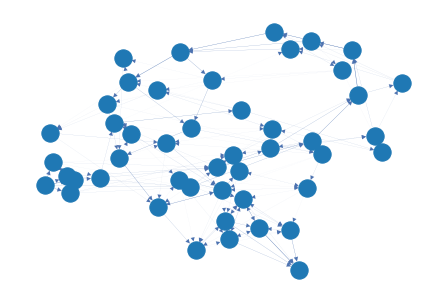

In [209]:
G = nx.DiGraph()
for i in range(forward_result.shape[0]):
    G.add_node(i,size=35)

for i in range(forward_result.shape[0]):
    for j in range(forward_result.shape[1]):

            value = forward_result[i][j]
            if value > 0.01:
                print(value)
                G.add_edge(i, j, label=value, weight=value, color = 'b')

weights = nx.get_edge_attributes(G,'weight').values()
colors = nx.get_edge_attributes(G,'color').values()

edges = G.edges()

nx.draw(G,
        edge_color=colors,
        width=list(weights))

In [210]:
from pyvis.network import Network
nt = Network('500px', '1600', directed=True)
nt.from_nx(G)
nt.show_buttons()
#nt.show_buttons(filter_=['physics'])
nt.save_graph("pyviz-test.html")

# Sum of viterbi paths

In [237]:
prob_list = []
total_result = np.zeros((len(model.states), len(model.states)))
for peptide in tqdm(allele_peptides):
    logp, path = model.viterbi(peptide)
    
    path_states = [node[0] for node in path]
    node_from = path_states.pop(0)
    while path_states:
        node_to = path_states.pop(0)
        # print(f"set {node_from} {node_to}")
        total_result[node_from][node_to] += 1
        node_from = node_to
    # break
    # forward_result = model.forward_backward(peptide)[0]
    # forward_result[forward_result < 0.1] = 0
    # total_result = total_result + forward_result

df = pd.DataFrame(total_result.T)

100%|████████████████████████████████████████████████████████████████| 12667/12667 [00:00<00:00, 15301.21it/s]


In [238]:
forward_result = df / len(allele_peptides)

0.11983895160653667
0.22302044683034658
0.1426541406805084
0.10902344675140128
0.10491829162390463
0.13341754164364095
0.2040735770111313
0.40901555222230995
0.2849925001973632
0.1664166732454409
0.16775874319096865
0.12331254440672614
0.15568011368121892
0.49056603773584906
0.11454961711533906
0.5509591852845978
0.422357306386674
0.14099628957132707
0.13689113444383041
0.4207784005684061
0.25546696139575276
0.12670719191600222
0.2784400410515513
0.2857030078155838
0.2646246151417068
0.11968106102470988
0.17028499250019735
0.1903370963922002
0.38785821425751954
0.4022262572037578
0.16294308044525144
0.11794426462461514
0.20486302992026525
0.10097102707823478
0.24370411304965658
0.21220494197521117
0.11818110049735533
0.10097102707823478
0.28704507776111154
0.3136496407989263
0.18133733322807294
0.12544406726138785
0.1327070340254204
0.4810926028262414
0.2687297702692034
0.13570695508012948
0.17952159153706482
0.4108312939133181


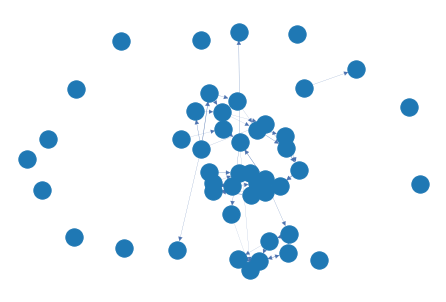

In [239]:
G = nx.DiGraph()
for i in range(forward_result.shape[0]):
    G.add_node(i,size=35)

for i in range(forward_result.shape[0]):
    for j in range(forward_result.shape[1]):

            value = forward_result[i][j]
            if value > 0.1:
                print(value)
                G.add_edge(i, j, label=value, weight=value, color = 'b')

weights = nx.get_edge_attributes(G,'weight').values()
colors = nx.get_edge_attributes(G,'color').values()

edges = G.edges()

nx.draw(G,
        edge_color=colors,
        width=list(weights))

In [240]:
from pyvis.network import Network
nt = Network('500px', '1600', directed=True)
nt.from_nx(G)
nt.show_buttons()
#nt.show_buttons(filter_=['physics'])
nt.save_graph("pyviz-test.html")

## Check same for multiple peptides

In [133]:
total_df = pd.DataFrame(np.zeros((len(model.states), len(model.states))))
counts_df = pd.DataFrame(np.zeros((len(model.states), len(model.states))))

In [143]:
target_peptides = np.array([peptide for peptide in allele_peptides if len(peptide) == 13])

In [144]:
len(target_peptides)

826

In [151]:
for peptide in target_peptides:
    logp, path = model.viterbi(peptide)
    forward_result = model.forward_backward(peptide)[0]
    total_df = total_df + (forward_result)
    counts_df = counts_df +  (forward_result > 0).astype(int)
# prob_list = []
# logp, path = model.viterbi(peptide)
# forward_result = model.forward_backward(peptide)[0]
#
# df = pd.DataFrame(forward_result)

In [152]:
total_df = total_df.divide(len(target_peptides))
total_df

,0,1,2,3,4,5,6,7,8,9,...,27,28,29,30,31,32,33,34,35,36
0,NaN,0.009682,0.036609,0.002298,0.014363,0.026045,0.053655,6.638754e-04,2.846538e-04,5.510073e-02,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.008766,NaN,0.026974,0.009450,0.006841,0.023767,0.043812,9.956663e-08,2.573296e-09,5.020162e-03,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.032512,0.008278,NaN,0.012438,0.015117,0.018079,0.037648,5.098594e-02,3.795715e-08,7.803561e-02,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.012428,0.002225,0.027729,NaN,0.015975,0.018818,0.020551,1.763683e-08,4.770559e-05,4.147381e-03,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.027324,0.013284,0.031886,0.014163,NaN,0.021712,0.036587,2.000192e-05,1.419424e-03,4.330241e-07,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.032646,0.007864,0.029187,0.011715,0.014844,NaN,0.069161,2.668967e-02,5.158798e-09,2.426742e-02,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0.050219,0.027904,0.080601,0.025243,0.032113,0.083259,NaN,5.138176e-02,6.357069e-03,6.098285e-02,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.134899e-03,3.578934e-02,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.155422e-02,NaN,1.874365e-02,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.972564e-02,1.395984e-02,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


0.09632816566344994
0.1014230497708048
0.08060116880992771
0.08325914121482583
0.0867253367389404
0.1053334858734559
0.08265783231877157
0.14651094302363543
0.11047619029608957
0.08856330426431948
0.11723672998177641
0.08309455735942588
0.08589038929467854
0.08516351416625963
0.09839013109670013
0.11668620715943573
0.18929878045956144
0.08895228811964877
0.09376985447916635
0.09026043431745684
0.09534765040293047
0.1655356231818382
0.23252235026531054
0.09222918563697767
0.11240324623880885
0.15216889676385584
0.1231559338949378
0.12614696573814302
0.16090808081185098
0.09845194598700795
0.2055331589466219
0.11749909866857762
0.1220083452476106
0.09955754816569046
0.187018122277983
0.08782060429122444
0.14573248943395728
0.10144556615403574
0.14782129344709397
0.2467552118862868
0.12112398252522877
0.10331560590193858
0.09761803996832705
0.16884277328017958
0.2185086563087243
0.1400915291098397
0.08943081768003139
0.15470664678169463
0.08324114699522445
0.21107993014998402
0.2486636164

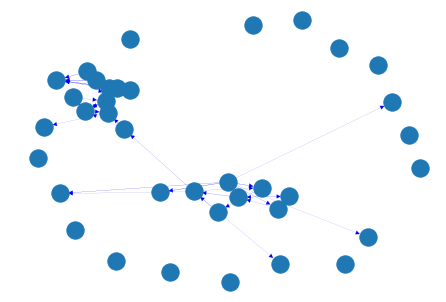

In [200]:
G = nx.DiGraph()
forward_result = total_df.values
for i in range(forward_result.shape[0]):
    G.add_node(i,size=35)



for i in range(forward_result.shape[0]):
    for j in range(forward_result.shape[1]):

            value = forward_result[i][j]
            if value > 0.08:
                print(value)
                G.add_edge(i, j, label=value, weight=value, color = 'b')

weights = nx.get_edge_attributes(G,'weight').values()
colors = nx.get_edge_attributes(G,'color').values()

edges = G.edges()

nx.draw(G,
        edge_color=colors,
        width=list(weights))

In [201]:
from pyvis.network import Network
nt = Network('500px', '1600', directed=True)
nt.from_nx(G)
nt.show_buttons()
#nt.show_buttons(filter_=['physics'])
nt.save_graph("pyviz-test_ten.html")

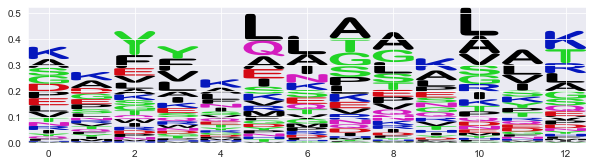

In [194]:
import logomaker
matrix = logomaker.alignment_to_matrix(target_peptides)
info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')

In [195]:
path_generator = nx.all_simple_paths(G, 35, 36, cutoff=15)


In [196]:
from tqdm import tqdm
paths = [path for path in tqdm(path_generator) if len(path) == 15]  # Might be very slow

1471811it [00:13, 106714.86it/s]


In [202]:
G.nodes

NodeView((0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36))

77.0
72.0
54.0
86.0
67.0
70.0
51.0
67.0
71.0
95.0
56.0
57.0
138.0
63.0
51.0
62.0
92.0
84.0
60.0
53.0
65.0
109.0
71.0
61.0
79.0
57.0
55.0
61.0
71.0
59.0
80.0
78.0
77.0
115.0
66.0
157.0
82.0
74.0
83.0
86.0
51.0
136.0
193.0
82.0
60.0
88.0
144.0
104.0
123.0
147.0
78.0
66.0
160.0
92.0
111.0
84.0
58.0
159.0
80.0
112.0
85.0
119.0
200.0
53.0
124.0
89.0
83.0
142.0
188.0
116.0
69.0
128.0
61.0
69.0
172.0
211.0


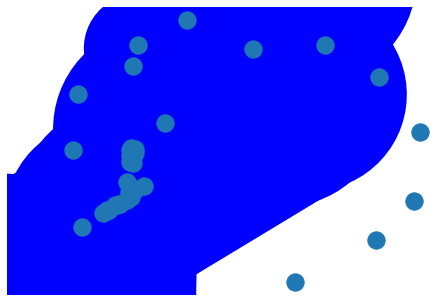

In [208]:
G = nx.DiGraph()

for i in range(len(model.states)):
    G.add_node(i,size=35)


transition_matrix = np.zeros((len(model.states), len(model.states)))
state_to_index = {state.name: i for i, state in enumerate(model.states)}


for peptide in target_peptides:
    logp, path = model.viterbi(peptide)
    for (idx_from, state_from), (idx_to, state_to) in zip(path, path[1:]):
        transition_matrix[idx_from][idx_to] += 1




for i in range(transition_matrix.shape[0]):
    for j in range(transition_matrix.shape[1]):
        value = transition_matrix[i][j]
        if value > 50:
            print(value)
            G.add_edge(i, j, label=value, weight=value, color = 'b')

weights = nx.get_edge_attributes(G,'weight').values()
colors = nx.get_edge_attributes(G,'color').values()

edges = G.edges()

nx.draw(G,
        edge_color=colors,
        width=list(weights))


In [209]:
from pyvis.network import Network
nt = Network('500px', '1600', directed=True)
nt.from_nx(G)
nt.show_buttons()
#nt.show_buttons(filter_=['physics'])
nt.save_graph("pyviz-test_viterbi.html")

In [ ]:
counts_from = df.sum(axis=0).sort_values(ascending=False)

In [ ]:
counts_to = df.sum(axis=1).sort_values(ascending=False)

In [ ]:
t = counts_from + counts_to

In [ ]:
counts_from[:8].index.intersection(counts_to.index)[:8]

In [ ]:
t.sort_values(ascending=False)

In [ ]:
df.mean(axis=0).sort_values(ascending=False)

In [ ]:
state_indexes

In [ ]:
forward_result.shape

In [ ]:
peptide

In [ ]:
forward_result[2][25] / np.sum(forward_result[2][forward_result[2] > -np.inf])

In [ ]:
np.ma.masked_invalid(forward_result[1]).sum()

In [ ]:
np.ma.masked_invalid(forward_result[2]).sum()

In [ ]:
np.ma.masked_invalid(forward_result[3]).sum()

In [ ]:
np.ma.masked_invalid(forward_result[4]).sum()

In [ ]:
np.ma.masked_invalid(forward_result[5]).sum()

In [ ]:
np.ma.masked_invalid(forward_result[6]).sum()

In [ ]:
np.ma.masked_invalid(forward_result[7]).sum()

In [ ]:
np.ma.masked_invalid(forward_result[8]).sum()

In [ ]:
np.ma.masked_invalid(forward_result[9]).sum()

In [ ]:
np.ma.masked_invalid(forward_result[10]).sum()

In [ ]:
np.ma.masked_invalid(forward_result[11]).sum()

In [ ]:
np.ma.masked_invalid(forward_result[12]).sum()

In [ ]:
per_state_information

In [ ]:
forward_result[3]

In [ ]:
forward_result[2]

In [ ]:
forward_result[2][25]

In [646]:
import logomaker
from collections import defaultdict
def probs_to_info_matrix(distribution):
    amino_acids = list(distribution.parameters[0].keys())
    dummy_df = pd.DataFrame(columns = sorted(amino_acids), index=[0],  dtype=float)
    for i, (acid, prob) in enumerate(distribution.parameters[0].items()):
        dummy_df.loc[0, acid] = prob
    dummy_df.index.name = "pos"
    info_matrix = logomaker.transform_matrix(dummy_df, from_type='probability', to_type='information')
    return info_matrix

per_state_information = dict()
per_level_information = defaultdict(float)
for state in model.states:
    if state not in [model.start, model.end]:
        info_matrix = probs_to_info_matrix(state.distribution)
        per_state_information[state.name] = sum(info_matrix.loc[0])
        # per_level_information[name_to_level[state.name]] += per_state_information[state.name]

In [647]:
len(peptide)

13

In [648]:
peptide

'LPWNSLPAKTLSK'

In [655]:

logp, path = model.viterbi(peptide)
print("Viterbi for Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( peptide ), logp, " ".join( state.name for idx, state in path[1:-1] ) ))

Viterbi for Sequence: 'LPWNSLPAKTLSK'  -- Log Probability: -39.298297824647406 -- Path: s006 s005 s011 s017 s018 s016 s023 s024 s034 s029 s031 s028 s034


In [656]:
print("Viterbi for Sequence: '{}'  -- Log Probability: {} -- Path: {}"
      .format(''.join( peptide ), logp, " ".join( str(np.round(state.distribution.parameters[0][aa],2)) for (idx, state), aa in zip(path[1:-1], peptide ) )))

Viterbi for Sequence: 'LPWNSLPAKTLSK'  -- Log Probability: -39.298297824647406 -- Path: 0.23 0.41 0.16 0.38 0.26 0.66 0.3 0.74 0.48 0.04 0.51 0.3 0.48


In [657]:
print(" ".join([str(np.round(per_state_information[state.name],2)) for idx, state  in  path[1:-1]]))

2.01 2.92 2.84 2.91 2.58 2.9 3.43 3.25 2.63 2.93 2.46 2.11 2.63


In [658]:
logp, path = model.maximum_a_posteriori(list(peptide))

print("Max a post for Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( peptide ), logp, " ".join( state.name for idx, state in path ) ))

Max a post for Sequence: 'LPWNSLPAKTLSK'  -- Log Probability: -1.7175090952294454 -- Path: s006 s005 s011 s017 s018 s016 s023 s024 s034 s029 s031 s028 s034


In [659]:
path[1][1].distribution.parameters[0]['L']

3.052977030260164e-05

In [660]:
peptide

'LPWNSLPAKTLSK'

In [661]:
model.log_probability(peptide)

-38.33398327253514

In [662]:
name_to_index = {state.name: i for i, state in enumerate(model.states)}


In [663]:
prob_list = []
logp, path = model.viterbi(peptide)
tr_matrix = model.dense_transition_matrix()
state_indexes = [idx for idx, state in path]
for state_from, state_to in zip(state_indexes, state_indexes[1:]):
    print(f"from {state_from} to {state_to}")
    prob_list.append(tr_matrix[state_from, state_to])
    
print(" ".join(map(str,[np.round(i, 2) for i in prob_list])))

from 35 to 6
from 6 to 5
from 5 to 11
from 11 to 17
from 17 to 18
from 18 to 16
from 16 to 23
from 23 to 24
from 24 to 34
from 34 to 29
from 29 to 31
from 31 to 28
from 28 to 34
from 34 to 36
0.3 0.22 0.16 0.05 0.17 0.22 0.24 0.2 0.13 0.14 0.23 0.19 0.18 0.21


In [678]:
prob_list = []
position_to_selected_index = dict()
logp, path = model.viterbi(peptide)
forward_result = model.forward(peptide)
state_indexes = [idx for idx, state in path[:-1]]
for i, state in enumerate(state_indexes):
    print(i, f"state was {state}")
    position_to_selected_index[i] = state
    prob_list.append(np.round(forward_result[i, state],2))
print(" ".join(map(str,prob_list)))

0 state was 35
1 state was 6
2 state was 5
3 state was 11
4 state was 17
5 state was 18
6 state was 16
7 state was 23
8 state was 24
9 state was 34
10 state was 29
11 state was 31
12 state was 28
13 state was 34
0.0 -2.67 -5.07 -8.5 -12.41 -15.52 -17.42 -20.05 -21.95 -24.54 -29.63 -31.78 -34.4 -36.83


In [679]:
forward_result.shape

(14, 37)

In [118]:
i = 13
for j in range(forward_result.shape[1]):
    value = forward_result[i][j]
    
    max_index = position_to_selected_index[i]
    if j != max_index and value != -np.inf:
        str_value = str(value).replace(".", ",")
        print(str_value)


-50,4600520636015
-55,21405822057615
-56,36003596353744
-56,997373669618774
-54,50139399504808
-52,94706512678872
-50,76380630327065
-48,52724039172562
-46,88377031338489
-53,223075304438005
-48,49380571078402
-55,70401866231975
-52,27786261931779
-46,937943909480616
-52,59163036233639
-42,90664192796635
-43,52717952445625
-48,474667683463366
-44,81011777665882
-49,1281484421489
-46,54491730773035
-41,390615694533196
-44,57803253113758
-42,635496583353174
-45,40487089168115
-39,66569747819228
-41,979145094292065
-40,511652274066655
-39,76514832095606
-35,21381535082042
-35,65452091015111
-37,39532014301484
-43,719290313315064
-35,95709152583941
-34,830719207902824


In [667]:
max_index

34

In [668]:
np.argmax(forward_result[1])

6

In [669]:
prob_list = []
logp, path = model.viterbi(peptide)
forward_result = model.backward(peptide)
state_indexes = [idx for idx, state in path[1:]]
for i, state in enumerate(state_indexes):
    print(i, f"state was {state}")
    prob_list.append(np.round(forward_result[i, state],2))
print(" ".join(map(str,prob_list)))

0 state was 6
1 state was 5
2 state was 11
3 state was 17
4 state was 18
5 state was 16
6 state was 23
7 state was 24
8 state was 34
9 state was 29
10 state was 31
11 state was 28
12 state was 34
13 state was 36
-39.38 -37.24 -34.55 -31.75 -29.37 -26.57 -24.84 -18.71 -19.05 -16.21 -13.44 -10.09 -6.56 0.0


In [698]:
forward_result[0]

array([-inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf,
       -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf,
       -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf,
       -inf, -inf,   0., -inf])

In [717]:
prob_list = []
logp, path = model.viterbi(peptide)
forward_result = model.forward_backward(peptide)[1]
state_indexes = [idx for idx, state in path[1:-1]]
for i, state in enumerate(state_indexes):
    print(i, f"state was {state}")
    # sum_of_row = np.abs(np.ma.masked_invalid(forward_result[i]).sum())
    # prob = np.log(np.abs(forward_result[i][state]) / sum_of_row)
    prob = forward_result[i][state]
    prob_list.append(np.round(prob,2))
print(" ".join(map(str,prob_list)))

0 state was 6
1 state was 5
2 state was 11
3 state was 17
4 state was 18
5 state was 16
6 state was 23
7 state was 24
8 state was 34
9 state was 29
10 state was 31
11 state was 28
12 state was 34
-0.02 -0.24 -0.08 -0.06 -0.06 -0.02 -0.02 -0.41 -0.2 -0.25 -0.27 -0.04 -0.07


In [731]:
i = 12
for j in range(forward_result.shape[1]):
    value = forward_result[i][j]
    
    max_index = np.argmax(forward_result[i])
    if j != max_index and value != -np.inf:
        str_value = str(value).replace(".", ",")
        print(str_value)

-10,86126806112312
-10,55765270572688
-9,962556305014438
-2,7228161413127197
-10,72286166970364
-10,674546988331066


In [701]:
peptide

'LPWNSLPAKTLSK'

In [702]:
prob_list = []
logp, path = model.viterbi(peptide)
forward_result = model.forward_backward(peptide)[0]

df = pd.DataFrame(forward_result)

In [703]:
# df.columns = [f"to_{i}" for i in df.columns]

In [704]:
df

,0,1,2,3,4,5,6,7,8,9,...,27,28,29,30,31,32,33,34,35,36
0,0.000000e+00,4.232722e-09,1.317698e-08,3.144491e-09,5.875311e-09,0.000072,0.000064,1.782929e-07,1.104761e-09,3.889515e-08,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
1,3.079552e-08,0.000000e+00,5.932723e-07,6.851946e-08,6.831725e-07,0.016619,0.000141,9.192608e-09,3.671169e-14,5.192040e-08,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
2,3.403792e-09,3.319711e-09,0.000000e+00,3.922392e-09,5.499564e-09,0.000025,0.000034,4.229513e-05,8.428534e-14,3.885012e-08,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
3,3.471277e-09,3.354099e-09,2.104491e-08,0.000000e+00,8.732707e-09,0.000060,0.000051,9.753766e-12,3.702945e-10,1.172032e-09,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
4,5.833162e-09,7.467081e-09,1.626566e-08,4.638564e-09,0.000000e+00,0.000056,0.000052,1.250033e-08,2.030254e-08,1.599249e-13,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
5,9.069517e-05,8.016978e-05,4.237545e-05,7.005910e-05,6.636601e-05,0.000000,0.052161,4.209938e-02,2.119399e-13,3.103825e-05,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
6,2.451349e-06,6.132323e-06,3.907008e-05,2.982600e-06,3.526286e-05,0.817567,0.000000,2.102078e-01,2.761060e-05,3.308772e-05,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
7,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,4.582103e-06,5.447917e-05,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
8,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,1.618886e-04,0.000000e+00,5.042212e-08,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
9,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,4.444897e-05,3.163726e-08,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000


In [705]:
counts_from = df.sum(axis=0).sort_values(ascending=False)

In [706]:
counts_to = df.sum(axis=1).sort_values(ascending=False)

In [707]:
t = counts_from + counts_to

In [708]:
counts_from[:8].index.intersection(counts_to.index)[:8]

Int64Index([34, 23, 6, 36, 16, 28, 31, 18], dtype='int64')

In [709]:
t.sort_values(ascending=False)

34    3.506909
23    2.275025
6     2.071302
16    1.982991
28    1.927722
31    1.905005
18    1.891699
17    1.890810
29    1.866945
11    1.840800
5     1.668819
24    1.631273
35    1.000000
36    1.000000
27    0.654771
7     0.520774
33    0.180189
15    0.063739
1     0.033526
21    0.029621
20    0.016620
13    0.015920
14    0.011535
10    0.007029
30    0.001060
26    0.000943
12    0.000907
22    0.000876
32    0.000715
9     0.000652
25    0.000451
8     0.000325
4     0.000283
0     0.000273
2     0.000251
3     0.000223
19    0.000018
dtype: float64

In [716]:
df.mean(axis=0).sort_values(ascending=False)

34    4.739066e-02
23    3.074358e-02
6     2.799057e-02
36    2.702703e-02
16    2.679718e-02
28    2.605030e-02
31    2.574331e-02
18    2.556350e-02
17    2.555148e-02
29    2.522898e-02
11    2.487568e-02
5     2.255161e-02
24    2.204423e-02
27    8.848253e-03
7     7.037485e-03
33    2.434991e-03
15    8.613423e-04
1     4.530511e-04
21    4.002771e-04
20    2.245956e-04
13    2.151289e-04
14    1.558747e-04
10    9.498681e-05
30    1.432414e-05
26    1.273794e-05
12    1.225138e-05
22    1.184356e-05
32    9.665413e-06
9     8.813849e-06
25    6.094582e-06
8     4.388021e-06
4     3.822527e-06
0     3.692077e-06
2     3.387311e-06
3     3.017869e-06
19    2.498684e-07
35    0.000000e+00
dtype: float64

In [144]:
state_indexes

[29, 25, 5, 26, 13, 12, 27, 15, 19, 16, 19, 17, 19, 28]

In [413]:
forward_result.shape

(13, 29)

In [212]:
peptide

'LPWNSLPAKTLSK'

In [134]:
forward_result[2][25] / np.sum(forward_result[2][forward_result[2] > -np.inf])

0.018860111727695247

In [149]:
np.ma.masked_invalid(forward_result[1]).sum()

-101.81839922943306

In [129]:
np.ma.masked_invalid(forward_result[2]).sum()

-111.79466151322342

In [138]:
np.ma.masked_invalid(forward_result[3]).sum()

-207.61530431374428

In [139]:
np.ma.masked_invalid(forward_result[4]).sum()

-248.45724733372174

In [140]:
np.ma.masked_invalid(forward_result[5]).sum()

-385.30555783838344

In [141]:
np.ma.masked_invalid(forward_result[6]).sum()

-299.01285775864375

In [142]:
np.ma.masked_invalid(forward_result[7]).sum()

-429.66226970451567

In [143]:
np.ma.masked_invalid(forward_result[8]).sum()

-247.90117657380048

In [144]:
np.ma.masked_invalid(forward_result[9]).sum()

-243.52481438094853

In [145]:
np.ma.masked_invalid(forward_result[10]).sum()

-101.58906085986405

In [146]:
np.ma.masked_invalid(forward_result[11]).sum()

-100.05514660799636

In [147]:
np.ma.masked_invalid(forward_result[12]).sum()

-26.840138297575997

In [155]:
per_state_information

{'s000': 0.6191820063679339,
 's001': 0.5404705141736063,
 's002': 0.4422933755192389,
 's003': 0.42839196825755965,
 's004': 0.6083797047231648,
 's005': 0.46029539963484184,
 's006': 1.9355271205884366,
 's007': 0.5254051269416767,
 's008': 1.4036819144201174,
 's009': 0.6530346626161714,
 's010': 0.7674784522037768,
 's011': 0.38917090545988453,
 's012': 1.8847521546484864,
 's013': 1.1378689138796028,
 's014': 0.2499125586048233,
 's015': 0.3955671949819537,
 's016': 0.369917526224787,
 's017': 0.9383000834820956,
 's018': 0.3998925232517925,
 's019': 0.4885741486687499,
 's020': 0.466500478812065,
 's021': 0.3421156911471375,
 's022': 0.7275999503576354,
 's023': 0.30630161445639376,
 's024': 0.2892401144095247,
 's025': 0.22545716228653642,
 's026': 0.2357797974631563,
 's027': 1.202519223386707,
 's028': 1.012496625321336}

In [136]:
forward_result[3]

array([-18.56196074, -13.74221367, -17.04396165, -22.50503426,
       -14.63014094,  -3.01322169, -10.78126053,  -0.18322389,
        -9.56777501,  -2.13754787, -15.27373332, -12.93869641,
       -17.84519834, -16.50125571, -14.74556163,         -inf,
               -inf,         -inf,         -inf,         -inf,
               -inf,         -inf,         -inf,         -inf,
               -inf,  -9.44809222,  -8.69642646,         -inf,
               -inf])

In [137]:
forward_result[2]

array([-14.27042619,  -9.45512754, -14.42573679, -14.31025811,
       -14.91636858,  -9.30959469,  -0.17008848,  -9.93057986,
        -3.39086407,  -6.82831389,         -inf,         -inf,
               -inf,         -inf,         -inf,         -inf,
               -inf,         -inf,         -inf,         -inf,
               -inf,         -inf,         -inf,         -inf,
               -inf,  -2.10845981, -12.6788435 ,         -inf,
               -inf])

In [120]:
forward_result[2][25]

-2.1084598066992655

In [30]:
bw_model.forward(allele_peptides[0])

array([[        -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,   0.        ,         -inf],
       [ -2.9879466 ,  -5.58099795,  -4.64763291,  -4.4516133 ,
         -6.98843885,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,         -inf,         -inf,         -inf,
                -inf,  -6.62823103,         -inf,         -inf,
                -inf,         -inf,         -inf],
  

In [33]:
bw_model.backward(allele_peptides[0])


array([[-34.18894134, -35.03657578, -33.73761064, -34.59059939,
        -34.19510768, -41.9499324 , -38.96991662, -41.95737941,
        -39.02703607, -37.00217388, -42.82718339, -42.68396685,
        -42.84132533, -42.87729494, -47.59539465, -47.08735152,
        -46.65612344, -46.80930789, -46.74258249, -46.78550379,
        -50.25550954, -49.46143184, -51.82324771, -49.74698978,
        -52.39325568, -35.43082919, -41.78034163, -46.67003185,
        -48.41603903, -34.91453714,         -inf],
       [-33.00075836, -30.19746749, -32.16425774, -33.72993644,
        -31.61500356, -36.46406418, -38.91798236, -36.60570465,
        -32.77241013, -36.45421461, -40.75282508, -40.86181315,
        -40.83968282, -40.76573621, -39.71972324, -44.29544785,
        -44.64362985, -44.73363526, -44.65753214, -44.77231776,
        -47.42838246, -45.14811076, -47.54911073, -45.7044437 ,
        -48.04382363, -32.02309105, -39.60656454, -43.18070868,
        -45.393379  , -33.68708127,         -inf],
  

In [34]:
bw_model.predict_proba(allele_peptides[0])

array([[3.41581895e-01, 4.21503038e-01, 1.49964977e-01, 3.81201375e-02,
        2.49993547e-02, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 2.38305972e-02, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00],
       [2.17776966e-05, 5.91254056e-02, 2.33332814e-03, 1.42007980e-07,
        6.00245939e-02, 3.58304214e-10, 4.95801886e-05, 8.68015740e-10,
        7.77591511e-04, 2.30034243e-02, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 8.54664155e-01,

In [40]:
bw_model.predict_log_proba(allele_peptides[0])

array([[-1.07416782e+00, -8.63928293e-01, -1.89735350e+00,
        -3.26701259e+00, -3.68890527e+00,            -inf,
                   -inf,            -inf,            -inf,
                   -inf,            -inf,            -inf,
                   -inf,            -inf,            -inf,
                   -inf,            -inf,            -inf,
                   -inf,            -inf,            -inf,
                   -inf,            -inf,            -inf,
                   -inf, -3.73678493e+00,            -inf,
                   -inf,            -inf],
       [-1.07346242e+01, -2.82809457e+00, -6.06045965e+00,
        -1.57673826e+01, -2.81300090e+00, -2.17496387e+01,
        -9.91191923e+00, -2.08648113e+01, -7.15930922e+00,
        -3.77211219e+00,            -inf,            -inf,
                   -inf,            -inf,            -inf,
                   -inf,            -inf,            -inf,
                   -inf,            -inf,            -inf,
             

In [43]:
np.max(bw_model.predict_log_proba(allele_peptides[0]), axis=0)

array([-1.07416782e+00, -8.63928293e-01, -1.89735350e+00, -3.26701259e+00,
       -2.81300090e+00, -3.01322169e+00, -1.70088475e-01, -1.83223890e-01,
       -3.39086407e+00, -2.13754787e+00, -2.70013353e+00, -4.57557501e+00,
       -2.66841056e-01, -1.85712074e+00, -3.53954165e-03, -7.58670450e-01,
       -2.16065308e+00, -4.00810482e-01, -8.83385279e-01, -1.22225118e+00,
       -2.72593430e+00, -6.11327246e-01, -3.57952589e-01, -1.08755677e+00,
       -1.30257275e+00, -1.57046688e-01, -4.22914498e-04, -3.42690168e-03,
       -3.27800711e-02])

In [44]:
bw_model.states[26]

{
    "class" : "State",
    "distribution" : {
        "class" : "Distribution",
        "dtype" : "str",
        "name" : "DiscreteDistribution",
        "parameters" : [
            {
                "A" : 0.12164656270185199,
                "C" : 0.006693162292725972,
                "D" : 0.02617722965605764,
                "E" : 0.0435330773637272,
                "F" : 0.04259363500764544,
                "G" : 0.037942606995498125,
                "H" : 0.03174732875835065,
                "I" : 0.06749511204607225,
                "K" : 0.08211169161057214,
                "L" : 0.09473261879002699,
                "M" : 0.028502037337257504,
                "N" : 0.03672194824716254,
                "P" : 0.04700972237104025,
                "Q" : 0.05852797162625894,
                "R" : 0.051963048169780875,
                "S" : 0.09327105105136284,
                "T" : 0.040829409421485184,
                "V" : 0.05063450435824783,
                "W" : 0.00765224932

In [28]:
from hmm_logic_methods import get_all_viterbi_paths_for_model_and_sequences
allele_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele_peptides)
allele_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele_peptides)


Model 0_run-13-14-15-16-17-18-29-st-viterbi-alg-5-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████| 12001/12001 [00:00<00:00, 20871.27it/s]


Select unique paths...
	Unique paths: 11514


100%|██████████| 11514/11514 [00:00<00:00, 38252.69it/s]


Model 0_run-13-14-15-16-17-18-29-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████| 12001/12001 [00:00<00:00, 16831.88it/s]


Select unique paths...
	Unique paths: 4243


100%|██████████| 4243/4243 [00:00<00:00, 36896.95it/s]


In [29]:
allele_bw_paths_df

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts
0,grouped_model-start>s003>s002>s001>s025>s006>s...,-7.063062,-0.371740,17,-49.064933,70
1,grouped_model-start>s003>s004>s001>s025>s006>s...,-7.413486,-0.390183,17,-48.305449,16
2,grouped_model-start>s003>s004>s002>s001>s025>s...,-7.851106,-0.392555,18,-52.350337,35
3,grouped_model-start>s003>s002>s001>s025>s006>s...,-7.533161,-0.396482,17,-49.973668,21
4,grouped_model-start>s002>s001>s025>s006>s007>s...,-7.162547,-0.397919,16,-46.046206,38
...,...,...,...,...,...,...
4238,grouped_model-start>s004>s002>s004>s002>s001>s...,-16.970119,-1.060632,14,-49.297371,1
4239,grouped_model-start>s025>s009>s026>s012>s014>s...,-21.567948,-1.078397,18,-58.017827,1
4240,grouped_model-start>s003>s000>s004>s001>s025>s...,-18.717206,-1.101012,15,-51.440685,1
4241,grouped_model-start>s003>s002>s004>s000>s004>s...,-19.358159,-1.138715,15,-56.639189,1


## Extract paths 
We have two approaches: all possible paths and decoy paths

# Extract all possible paths
* precision used to crop transitions
* min and max path lengths are  min/max of (TARGET_LENGTHS)

In [13]:
from hmm_logic_methods import get_all_paths_with_probs, get_model_representation

# code for saving paths do model folder
def save_paths_df(paths_df, model, file_name):
    print(f"model {model.name}")
    
    TARGET_PATH_TO_FILES = f"{name_to_model_root[model.name]}{model.name}/"
    paths_df.to_csv("{}/{}".format(TARGET_PATH_TO_FILES,file_name),sep=";", index=False)

In [14]:
# exctract paths
if APPROACH == 'total_paths':
    for model_key, model in per_name_binding_model.items():
        print(model_key)
        TARGET_LENGTHS = name_to_target_lengths[model_key]
        paths_df , edge_to_prob = get_all_paths_with_probs(model, cutoff=max(TARGET_LENGTHS), precision=3, min_path_length=min(TARGET_LENGTHS), max_path_length=max(TARGET_LENGTHS))
        save_paths_df(paths_df, model,"total_paths_df.csv")
        break

# Extract only viterbi paths for decoy for models
* we need some data here

## Preparation: get decoy data

In [15]:
from mhcgnomes import parse
# decoy data
def defineOrganism(allele_name):
    parse_result = parse(allele_name)
    if parse_result.is_mouse:
        return "Mouse"
    elif parse_result.is_human:
        return "Human"
    else:
        print("organism not found")
        return None

def defineClass(allele_name):
    parse_result = parse(allele_name)
    if parse_result.has_mhc_class:
        if parse_result.is_class1:
            return 'I'
        elif parse_result.is_class2:
            print('Class II data')
            return 'II'
        else:
            print("Not class I or class II???!")
    else:
        print("Result without class")
    return None

per_allele_decoy_peptides = dict()
for allele_name in ALLELES:
    organism =  defineOrganism(allele_name).lower()
    class_to_use = defineClass(allele_name)
    DECOY_DATA_PATH = f"D:\Google Drive\Work\ITMO\data\decoy\sampled_decoy_data_{organism}_class_{class_to_use}.csv"
    decoy_df =  pd.read_csv(DECOY_DATA_PATH)
    decoy_df['length'] = decoy_df['peptide'].str.len()
    per_allele_decoy_peptides[allele_name] = decoy_df.copy()[decoy_df['length'].isin(TARGET_LENGTHS)]['peptide'].values

peptides_for_analysis = np.unique(np.concatenate([value for key, value in per_allele_decoy_peptides.items()
                                                  if key in selected_alleles]))

Class II data


In [16]:
len(peptides_for_analysis)

934350

## Calculate viterbi paths

In [17]:
sample_model = per_name_binding_model[list(per_name_binding_model.keys())[0]]
peptide = peptides_for_analysis[0]
logp, path = sample_model.viterbi(peptide)
print("Viterbi for Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( peptide ), logp, " ".join( state.name for idx, state in path[1:-1] ) ))

Viterbi for Sequence: 'AAAAAAAAAAAAA'  -- Log Probability: -39.89893213993516 -- Path: s000 s013 s019 s021 s028 s030 s028 s030 s028 s030 s028 s030 s028


In [18]:
%%time
from hmm_logic_methods import get_all_viterbi_paths_for_model_and_sequences

# exctract paths
for model_key, model in per_name_binding_model.items():
    print(model_key)
    TARGET_LENGTHS = name_to_target_lengths[model_key]
    paths_df = get_all_viterbi_paths_for_model_and_sequences(model, peptides_for_analysis)
    save_paths_df(paths_df, model,"viterbi_paths_df.csv")
    
# df_bw_paths = get_all_viterbi_paths_for_model_and_sequences(model_bw, peptides_for_analysis)
# df_bwv_paths = get_all_viterbi_paths_for_model_and_sequences(model_bwv, peptides_for_analysis)
# df_v_paths = get_all_viterbi_paths_for_model_and_sequences(model_v, peptides_for_analysis)

9_run-13-14-15-16-17-18-35-st-viterbi-alg-5-min_iters_model-HLA_DRB1_01_01-0
Model 9_run-13-14-15-16-17-18-35-st-viterbi-alg-5-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████| 934350/934350 [00:56<00:00, 16626.84it/s]


Select unique paths...
	Unique paths: 934122


100%|██████████████████████████████████████████████████████████████| 934122/934122 [00:13<00:00, 68584.58it/s]


model 9_run-13-14-15-16-17-18-35-st-viterbi-alg-5-min_iters_model-HLA_DRB1_01_01-0
9_run-13-14-15-16-17-18-35-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0_plus_viterbi
Model 9_run-13-14-15-16-17-18-35-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0_plus_viterbi
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████| 934350/934350 [00:48<00:00, 19445.35it/s]


... (111 outputs left out)

100%|██████████████████████████████████████████████████████████████| 934350/934350 [00:44<00:00, 21109.31it/s]


Select unique paths...
	Unique paths: 80449


100%|████████████████████████████████████████████████████████████████| 80449/80449 [00:01<00:00, 62267.05it/s]


model 0_run-13-14-15-16-17-18-35-st-baum-welch-alg-5-min_iters_model-HLA_DRB1_01_01-0
Wall time: 29min 15s


In [19]:
paths_df['path'].str.contains('s001').astype(int)

0        1
1        1
2        1
3        1
4        1
        ..
80444    0
80445    0
80446    0
80447    0
80448    1
Name: path, Length: 80449, dtype: int32

In [20]:
import itertools

In [66]:
from itertools import permutations

In [67]:
columns_to_analyse = list()
for i in range(25):
    target_column = f's{i:03d}'
    print(target_column)
    columns_to_analyse.append(target_column)
    paths_df[target_column] = paths_df['path'].str.contains(target_column).astype(int)

s000
s001
s002
s003
s004
s005
s006
s007
s008
s009
s010
s011
s012
s013
s014
s015
s016
s017
s018
s019
s020
s021
s022
s023
s024


In [68]:
paths_df[['path'] + [f's{i:03d}' for i in range(25)]]

,path,s000,s001,s002,s003,s004,s005,s006,s007,s008,...,s015,s016,s017,s018,s019,s020,s021,s022,s023,s024
0,grouped_model-start>s001>s002>s005>s010>s012>s...,0,1,1,0,0,1,0,0,0,...,0,1,0,1,0,0,1,0,1,0
1,grouped_model-start>s001>s002>s005>s010>s013>s...,0,1,1,0,0,1,0,0,0,...,0,1,0,1,0,0,1,0,1,0
2,grouped_model-start>s001>s002>s005>s010>s012>s...,0,1,1,0,0,1,0,0,0,...,0,1,0,0,1,0,1,0,1,0
3,grouped_model-start>s001>s002>s005>s010>s011>s...,0,1,1,0,0,1,0,0,0,...,0,1,0,1,0,0,1,0,1,0
4,grouped_model-start>s001>s002>s005>s010>s014>s...,0,1,1,0,0,1,0,0,0,...,0,1,0,1,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2193,grouped_model-start>s004>s009>s005>s013>s014>s...,0,0,0,0,1,1,0,0,0,...,1,0,1,0,0,0,1,0,0,1
2194,grouped_model-start>s000>s003>s008>s010>s014>s...,1,0,0,1,0,0,0,0,1,...,1,1,0,0,0,0,0,1,1,0
2195,grouped_model-start>s000>s003>s005>s013>s014>s...,1,0,0,1,0,1,0,0,0,...,1,0,1,0,0,0,1,0,0,1
2196,grouped_model-start>s000>s009>s005>s013>s014>s...,1,0,0,0,0,1,0,0,0,...,1,1,0,0,0,0,1,0,1,0


In [48]:
paths_df

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts,s000,s001,s002,s003,...,s016,s017,s018,s019,s020,s021,s022,s023,s024,distance_to_first
0,grouped_model-start>s001>s005>s012>s014>s012>s...,-10.305756,-0.936887,9,-30.469166,16,0,1,0,0,...,0,1,0,0,0,1,0,0,1,2
1,grouped_model-start>s001>s009>s012>s014>s012>s...,-10.472337,-0.952031,9,-32.526799,11,0,1,0,0,...,0,1,0,0,0,1,0,0,1,0
2,grouped_model-start>s001>s005>s012>s014>s012>s...,-10.496306,-0.954210,9,-31.780450,13,0,1,0,0,...,0,1,1,0,0,1,0,0,1,3
3,grouped_model-start>s001>s005>s012>s014>s012>s...,-10.536506,-0.957864,9,-31.406283,14,0,1,0,0,...,0,0,0,0,0,1,0,0,1,4
4,grouped_model-start>s001>s005>s012>s014>s017>s...,-10.614781,-0.964980,9,-31.537344,13,0,1,0,0,...,0,1,0,0,0,1,0,1,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
662627,grouped_model-start>s003>s002>s005>s008>s009>s...,-32.925953,-2.743829,10,-43.970726,1,0,0,1,1,...,0,0,1,1,0,0,0,1,1,11
662628,grouped_model-start>s003>s001>s000>s003>s002>s...,-32.995807,-2.749651,10,-47.477605,1,1,1,1,1,...,0,0,0,0,0,0,0,1,0,12
662629,grouped_model-start>s001>s002>s000>s004>s002>s...,-33.149295,-2.762441,10,-45.600153,1,1,1,1,0,...,0,0,0,0,0,0,0,0,1,10
662630,grouped_model-start>s003>s002>s008>s009>s007>s...,-33.270920,-2.772577,10,-46.846554,1,0,0,1,1,...,0,1,1,0,0,0,1,0,0,12


In [45]:
selected_row = paths_df[columns_to_analyse].iloc[1].values

In [46]:
selected_row

array([0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       0, 0, 1])

In [25]:
result = np.abs(np.subtract(paths_df[columns_to_analyse].values, selected_row))

In [26]:
np.sum(result, axis=1)

array([ 2,  0,  3, ..., 10, 12, 11])

In [28]:
paths_df['distance_to_first'] = np.sum(np.abs(np.subtract(paths_df[columns_to_analyse].values, selected_row)), axis=1)

In [34]:
paths_df['distance_to_first'].value_counts()

10    117250
9     102309
8     102045
11     82038
12     65205
7      63711
6      45307
13     29611
5      20469
14     15343
4       9985
15      4182
3       2947
16      1068
2        885
17       166
1        109
0          2
Name: distance_to_first, dtype: int64

In [37]:
paths_df[paths_df['distance_to_first'] == 0]['path'].values

array(['grouped_model-start>s001>s009>s012>s014>s012>s014>s017>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s012>s014>s017>s024>s021>s024>s021>grouped_model-end'],
      dtype=object)

In [53]:
paths_df[paths_df['distance_to_first'] == 1]['path'].values

array(['grouped_model-start>s001>s009>s012>s014>s012>s018>s017>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s012>s014>s017>s024>s023>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s007>s012>s014>s012>s014>s017>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s012>s014>s017>s018>s017>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s012>s011>s012>s014>s017>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s012>s014>s012>s011>s017>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s012>s014>s017>s024>s020>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s007>s014>s012>s014>s017>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s012>s014>s012>s014>s018>s017>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s006>s009>s012>s014>s017>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s012>s014>s012>s016>s0

In [52]:
paths_df['path'].loc[:25].values

array(['grouped_model-start>s001>s005>s012>s014>s012>s014>s017>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s012>s014>s012>s014>s017>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s005>s012>s014>s012>s018>s017>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s005>s012>s014>s012>s014>s015>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s005>s012>s014>s017>s024>s023>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s012>s014>s012>s018>s017>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s007>s012>s014>s019>s023>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s005>s007>s012>s014>s019>s023>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s007>s012>s014>s015>s023>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s012>s014>s012>s014>s015>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s005>s007>s012>s014>s015>s023>s024>s0

In [33]:
paths_df

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts,s000,s001,s002,s003,...,s016,s017,s018,s019,s020,s021,s022,s023,s024,distance_to_first
0,grouped_model-start>s001>s005>s012>s014>s012>s...,-10.305756,-0.936887,9,-30.469166,16,0,1,0,0,...,0,1,0,0,0,1,0,0,1,2
1,grouped_model-start>s001>s009>s012>s014>s012>s...,-10.472337,-0.952031,9,-32.526799,11,0,1,0,0,...,0,1,0,0,0,1,0,0,1,0
2,grouped_model-start>s001>s005>s012>s014>s012>s...,-10.496306,-0.954210,9,-31.780450,13,0,1,0,0,...,0,1,1,0,0,1,0,0,1,3
3,grouped_model-start>s001>s005>s012>s014>s012>s...,-10.536506,-0.957864,9,-31.406283,14,0,1,0,0,...,0,0,0,0,0,1,0,0,1,4
4,grouped_model-start>s001>s005>s012>s014>s017>s...,-10.614781,-0.964980,9,-31.537344,13,0,1,0,0,...,0,1,0,0,0,1,0,1,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
662627,grouped_model-start>s003>s002>s005>s008>s009>s...,-32.925953,-2.743829,10,-43.970726,1,0,0,1,1,...,0,0,1,1,0,0,0,1,1,11
662628,grouped_model-start>s003>s001>s000>s003>s002>s...,-32.995807,-2.749651,10,-47.477605,1,1,1,1,1,...,0,0,0,0,0,0,0,1,0,12
662629,grouped_model-start>s001>s002>s000>s004>s002>s...,-33.149295,-2.762441,10,-45.600153,1,1,1,1,0,...,0,0,0,0,0,0,0,0,1,10
662630,grouped_model-start>s003>s002>s008>s009>s007>s...,-33.270920,-2.772577,10,-46.846554,1,0,0,1,1,...,0,1,1,0,0,0,1,0,0,12


In [66]:
paths_df

array(['grouped_model-start>s001>s005>s012>s014>s012>s014>s017>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s009>s012>s014>s012>s014>s017>s024>s021>grouped_model-end',
       'grouped_model-start>s001>s005>s012>s014>s012>s018>s017>s024>s021>grouped_model-end',
       ...,
       'grouped_model-start>s001>s002>s000>s004>s002>s009>s008>s013>s015>s024>grouped_model-end',
       'grouped_model-start>s003>s002>s008>s009>s007>s008>s010>s018>s017>s022>grouped_model-end',
       'grouped_model-start>s004>s001>s004>s002>s008>s013>s015>s018>s024>grouped_model-end'],
      dtype=object)

In [49]:
distance_matrix(paths_df[columns_to_analyse], paths_df[columns_to_analyse])

MemoryError: Unable to allocate 3.19 TiB for an array with shape (662632, 662632) and data type float64

In [ ]:
for i in paths_df.iterrows():
    

In [41]:
paths_df.iloc[7][columns_to_analyse]

s000    0
s001    1
s002    0
s003    0
s004    0
s005    1
s006    0
s007    1
s008    0
s009    0
s010    0
s011    0
s012    1
s013    0
s014    1
s015    0
s016    0
s017    0
s018    0
s019    1
s020    0
s021    1
s022    0
s023    1
s024    1
Name: 7, dtype: object

In [35]:
paths_df.iloc[1][columns_to_analyse] - paths_df.iloc[4][columns_to_analyse]

s000    0
s001    0
s002    0
s003    0
s004    0
s005    0
s006    0
s007    0
s008    0
s009    0
s010    0
s011    0
s012    0
s013    0
s014    0
s015    0
s016    0
s017    0
s018    0
s019    0
s020    0
s021    0
s022    0
s023    0
s024    0
dtype: object

In [24]:
paths_df['path'].str.split(">", expand = True)

,0,1,2,3,4,5,6,7,8,9,10,11
0,grouped_model-start,s001,s005,s012,s014,s012,s014,s017,s024,s021,grouped_model-end,None
1,grouped_model-start,s001,s009,s012,s014,s012,s014,s017,s024,s021,grouped_model-end,None
2,grouped_model-start,s001,s005,s012,s014,s012,s018,s017,s024,s021,grouped_model-end,None
3,grouped_model-start,s001,s005,s012,s014,s012,s014,s015,s024,s021,grouped_model-end,None
4,grouped_model-start,s001,s005,s012,s014,s017,s024,s023,s024,s021,grouped_model-end,None
...,...,...,...,...,...,...,...,...,...,...,...,...
662627,grouped_model-start,s003,s002,s005,s008,s009,s012,s019,s018,s024,s023,grouped_model-end
662628,grouped_model-start,s003,s001,s000,s003,s002,s007,s010,s014,s015,s023,grouped_model-end
662629,grouped_model-start,s001,s002,s000,s004,s002,s009,s008,s013,s015,s024,grouped_model-end
662630,grouped_model-start,s003,s002,s008,s009,s007,s008,s010,s018,s017,s022,grouped_model-end


In [ ]:
for i in range(26):


## Compare paths for decoy and training data

In [20]:
allele1 = 'HLA-A*01:01'
allele2 = 'HLA-A*03:01'
allele3 = 'HLA-A*02:01'

allele1_undescore_only = allele1.replace('-', '_').replace('*', '_').replace(':', '_')
allele2_undescore_only = allele2.replace('-', '_').replace('*', '_').replace(':', '_')
allele3_undescore_only = allele3.replace('-', '_').replace('*', '_').replace(':', '_')

bw_model_name = f'0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-{allele1_undescore_only}+{allele2_undescore_only}-0'
v_model_name = f'0_run-9-10-11-12-25-st-viterbi-alg-5-min_iters_model-{allele1_undescore_only}+{allele2_undescore_only}-0'

# bw_model_name = f'0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-{allele1_undescore_only}+{allele3_undescore_only}+{allele2_undescore_only}-0'
# v_model_name = f'0_run-9-10-25-st-viterbi-alg-5-min_iters_model-{allele1_undescore_only}+{allele3_undescore_only}+{allele2_undescore_only}-0'


In [21]:
from hmm_logic_methods import get_all_viterbi_paths_for_model_and_sequences

# exctract paths
# bw_model = per_name_binding_model[bw_model_name]
v_model = per_name_binding_model[v_model_name]

# decoy_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, peptides_for_analysis)
decoy_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, peptides_for_analysis)


Model 0_run-9-10-11-12-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████| 1598170/1598170 [00:42<00:00, 37264.55it/s]


Select unique paths...
	Unique paths: 1479846


100%|████████████████████████████████████████████████████████████| 1479846/1479846 [00:15<00:00, 93013.71it/s]


In [22]:
# Get allele peptides 
allele1_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele1][0][target_length] for target_length in TARGET_LENGTHS])
allele2_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele2][0][target_length] for target_length in TARGET_LENGTHS])

In [23]:
# allele1_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele1_peptides)
allele1_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele1_peptides)
# allele2_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele2_peptides)
allele2_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele2_peptides)

Model 0_run-9-10-11-12-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|████████████████████████████████████████████████████████████████| 10052/10052 [00:00<00:00, 37368.22it/s]


Select unique paths...
	Unique paths: 9687


100%|██████████████████████████████████████████████████████████████████| 9687/9687 [00:00<00:00, 86494.58it/s]


Model 0_run-9-10-11-12-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 8209/8209 [00:00<00:00, 40437.18it/s]


Select unique paths...
	Unique paths: 7579


100%|██████████████████████████████████████████████████████████████████| 7579/7579 [00:00<00:00, 86129.38it/s]


In [ ]:
def check_intersection(decoy_paths_df, allele_path_df, allele_name):
    print("for allele", allele_name)
    decoy_paths = set(decoy_paths_df['path'])
    allele_paths = set(allele_path_df['path'])
    print(f" len of decoy = {len(decoy_paths)}, len of allele {len(allele_paths)}, intersection {len(decoy_paths.intersection(allele_paths))}")

    


In [ ]:
print("BW")
check_intersection(decoy_bw_paths_df, allele1_bw_paths_df, allele1)
check_intersection(decoy_bw_paths_df, allele2_bw_paths_df, allele2)
print("V")
check_intersection(decoy_v_paths_df, allele1_v_paths_df, allele1)
check_intersection(decoy_v_paths_df, allele2_v_paths_df, allele2)


In [26]:
title_font_size=20
from typing import List, NewType, Dict

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_venn import venn3, venn2, venn2_circles, venn3_circles, venn3_unweighted 

Peptides = NewType('Peptides', np.ndarray)
ListOfPerSuffixPeptides = List[Dict[str, Peptides]]

def venn_intersection(data_list: List[Peptides], labels: List[str], fixed_size=False, font_size=16, **kwargs) -> None:
    if len(data_list) == 2:
        v = venn2(subsets=[set(item) for item in data_list], set_labels=labels, **kwargs)
        for text in v.set_labels:
            text.set_fontsize(font_size)    
        for x in range(len(v.subset_labels)):
            if v.subset_labels[x] is not None:
                v.subset_labels[x].set_fontsize(font_size)
    elif len(data_list) == 3:
        v = venn3_unweighted(subsets=[set(item) for item in data_list], set_labels=labels, **kwargs)
        for text in v.set_labels:
            text.set_fontsize(font_size)    
        for x in range(len(v.subset_labels)):
            if v.subset_labels[x] is not None:
                v.subset_labels[x].set_fontsize(font_size)
    else:
        print("Can do only 2 or 3 sets")



def check_intersection2(decoy_paths_df, allele1_paths_df, allele2_paths_df, ax, allele1_name, allele2_name):
    decoy_paths = decoy_paths_df['path'].values
    allele1_paths = allele1_paths_df['path'].values
    allele2_paths = allele2_paths_df['path'].values
    data_list = [decoy_paths, allele1_paths, allele2_paths]
    labels = ['Decoy', allele1_name, allele2_name]
    font_size=16
    venn_intersection(data_list, labels=labels, ax=ax, font_size=font_size)


In [ ]:

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(decoy_bw_paths_df, allele1_bw_paths_df, allele2_bw_paths_df, ax, allele1, allele2)
ax.set_title('BW model',  fontsize=title_font_size)



In [ ]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(decoy_v_paths_df, allele1_v_paths_df, allele2_v_paths_df,ax, allele1, allele2)
ax.set_title('V model',  fontsize=title_font_size)


In [ ]:
allele2_v_paths_df['path'].iloc[1]

In [24]:
allele1_v_paths_df['exp_prob'] = np.exp(allele1_v_paths_df['prob'])
allele2_v_paths_df['exp_prob'] = np.exp(allele2_v_paths_df['prob'])
decoy_v_paths_df['exp_prob'] = np.exp(decoy_v_paths_df['prob'])

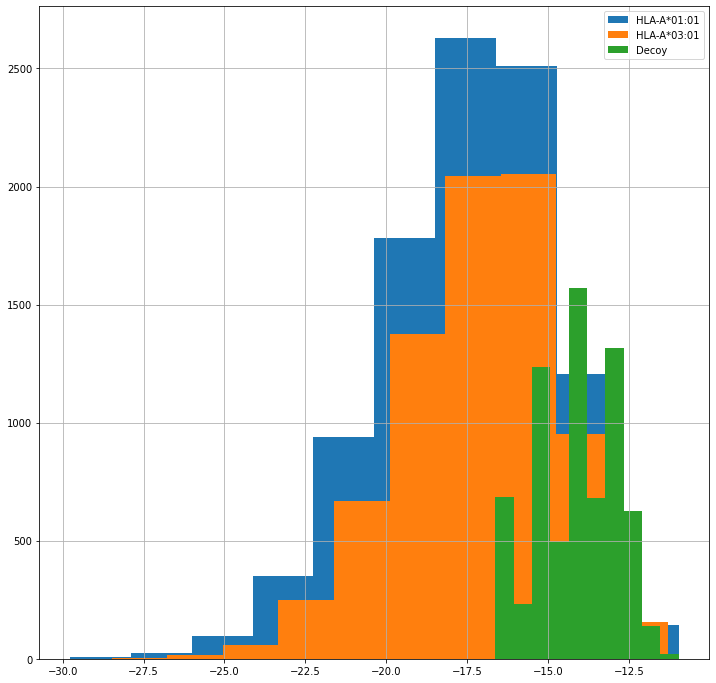

In [33]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[12, 12])
        
allele1_v_paths_df['prob'].hist().plot(ax=ax, label=allele1)
allele2_v_paths_df['prob'].hist().plot(ax=ax, label=allele2)
decoy_v_paths_df[:7000]['prob'].hist().plot(ax=ax, label='decoy')
plt.legend([allele1, allele2, 'Decoy'])

In [ ]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])
        
allele1_v_paths_df['exp_prob'].cumsum().plot(ax=ax)
allele2_v_paths_df['exp_prob'].cumsum().plot(ax=ax)
decoy_v_paths_df[:7000]['exp_prob'].cumsum().plot(ax=ax)


# Compare binders vs non-binders vs decoy

In [ ]:
# Get allele peptides 
allele1_b_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele1][0][target_length] for target_length in TARGET_LENGTHS])
allele2_b_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele2][0][target_length] for target_length in TARGET_LENGTHS])
# non-binders peptides
allele1_nb_peptides = np.concatenate([per_allele_per_kfold_per_length_non_binders_train[allele1][0][target_length] for target_length in TARGET_LENGTHS])
allele2_nb_peptides = np.concatenate([per_allele_per_kfold_per_length_non_binders_train[allele2][0][target_length] for target_length in TARGET_LENGTHS])

In [ ]:
allele1_b_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele1_b_peptides)
allele1_nb_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele1_nb_peptides)

allele1_b_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele1_b_peptides)
allele1_nb_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele1_nb_peptides)

allele2_b_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele2_b_peptides)
allele2_nb_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele2_nb_peptides)

allele2_b_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele2_b_peptides)
allele2_nb_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele2_nb_peptides)

In [ ]:
data_dict = {
    "V": {
        allele1: {"B":allele1_b_v_paths_df, "NB":allele1_nb_v_paths_df},
        allele2: {"B":allele2_b_v_paths_df, "NB": allele2_nb_v_paths_df},
        "decoy": decoy_v_paths_df
    },
    "BW": {
        allele1: {"B":allele1_b_bw_paths_df, "NB":allele1_nb_bw_paths_df},
        allele2: {"B":allele2_b_bw_paths_df, "NB": allele2_nb_bw_paths_df},
        "decoy": decoy_bw_paths_df
    }
}

In [ ]:
len(allele1_nb_peptides)
len(allele2_nb_peptides)

In [ ]:
fig, axes = plt.subplots(ncols=2, nrows=2, figsize=[20, 20])

for i, algo in enumerate(["V", "BW"]):
    for j, allele_name in enumerate([allele1, allele2]):
        binder_paths = data_dict[algo][allele_name]["B"]
        non_binder_paths = data_dict[algo][allele_name]["NB"]
        decoy_paths = data_dict[algo]['decoy']
        check_intersection2(decoy_paths, binder_paths, non_binder_paths,axes[j][i], allele_name + "B", allele_name + "NB")
        axes[j][i].set_title(f'{algo} model, allele {allele_name}',  fontsize=title_font_size)


        

In [ ]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(decoy_v_paths_df, allele1_b_v_paths_df, allele1_nb_v_paths_df,ax, allele1 + "B", allele1 + "NB")
ax.set_title(f'V model, allele {allele1}',  fontsize=title_font_size)


In [ ]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(decoy_bw_paths_df, allele1_b_bw_paths_df, allele1_nb_bw_paths_df,ax, allele1 + "B", allele1 + "NB")
ax.set_title(f'BW model, allele {allele1}',  fontsize=title_font_size)


## Check train paths vs test paths

In [64]:
# Get allele peptides 
allele1_tr_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele1][0][target_length] for target_length in TARGET_LENGTHS])
allele2_tr_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele2][0][target_length] for target_length in TARGET_LENGTHS])
# non-binders peptides
allele1_te_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_test[allele1][0][target_length] for target_length in TARGET_LENGTHS])
allele2_te_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_test[allele2][0][target_length] for target_length in TARGET_LENGTHS])

In [65]:
allele1_tr_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele1_tr_peptides)
allele1_te_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele1_te_peptides)

allele1_tr_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele1_tr_peptides)
allele1_te_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele1_te_peptides)

allele2_tr_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele2_tr_peptides)
allele2_te_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele2_te_peptides)

allele2_tr_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele2_tr_peptides)
allele2_te_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele2_te_peptides)

Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 7516/7516 [00:00<00:00, 43441.05it/s]


Select unique paths...
	Unique paths: 1005


100%|██████████████████████████████████████████████████████████████████| 1005/1005 [00:00<00:00, 59097.07it/s]


Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 1881/1881 [00:00<00:00, 34835.09it/s]


... (22 outputs left out)

Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 1829/1829 [00:00<00:00, 25056.20it/s]


Select unique paths...
	Unique paths: 1795


100%|██████████████████████████████████████████████████████████████████| 1795/1795 [00:00<00:00, 49861.09it/s]


In [66]:
data_dict = {
    "V": {
        allele1: {"Train":allele1_tr_v_paths_df, "Test":allele1_te_v_paths_df},
        allele2: {"Train":allele2_tr_v_paths_df, "Test": allele2_te_v_paths_df},
        "decoy": decoy_v_paths_df
    },
    "BW": {
        allele1: {"Train":allele1_tr_bw_paths_df, "Test":allele1_te_bw_paths_df},
        allele2: {"Train":allele2_tr_bw_paths_df, "Test": allele2_te_bw_paths_df},
        "decoy": decoy_bw_paths_df
    }
}

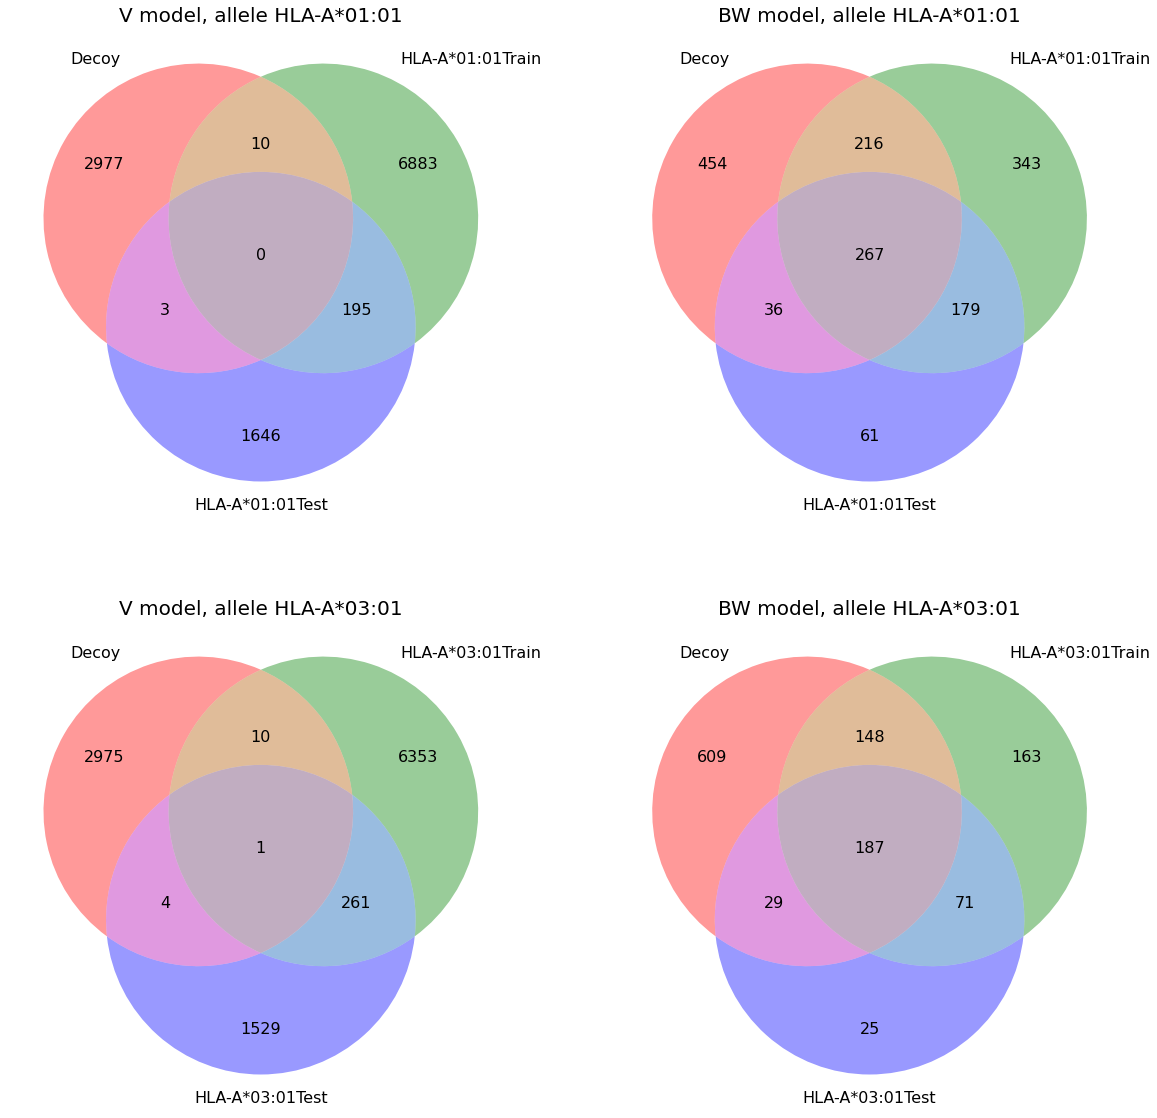

In [67]:
fig, axes = plt.subplots(ncols=2, nrows=2, figsize=[20, 20])

for i, algo in enumerate(["V", "BW"]):
    for j, allele_name in enumerate([allele1, allele2]):
        binder_paths = data_dict[algo][allele_name]["Train"]
        non_binder_paths = data_dict[algo][allele_name]["Test"]
        decoy_paths = data_dict[algo]['decoy']
        check_intersection2(decoy_paths, binder_paths, non_binder_paths,axes[j][i], allele_name + "Train", allele_name + "Test")
        axes[j][i].set_title(f'{algo} model, allele {allele_name}',  fontsize=title_font_size)



In [68]:
allele1_tr_bw_paths_df['peptide_cnts'].value_counts()

1      418
2      168
3       85
4       62
6       38
5       35
8       22
7       15
9       15
10      14
14      11
17      10
13      10
11       8
12       7
21       5
15       5
32       5
19       5
23       5
35       4
16       4
20       3
31       3
18       3
22       3
26       3
50       2
28       2
33       2
37       2
29       2
97       2
117      2
25       2
123      2
34       1
109      1
54       1
36       1
72       1
80       1
58       1
184      1
47       1
49       1
30       1
55       1
281      1
139      1
237      1
93       1
634      1
39       1
67       1
149      1
44       1
Name: peptide_cnts, dtype: int64

In [69]:
allele1_te_v_paths_df['peptide_cnts'].value_counts()

1    1812
2      28
3       3
4       1
Name: peptide_cnts, dtype: int64

In [70]:
allele1_tr_v_paths_df['peptide_cnts'].value_counts()

1    6745
2     281
3      41
4      19
5       2
Name: peptide_cnts, dtype: int64

In [71]:
decoy_v_paths_df['peptide_cnts'].value_counts()

1    2984
2       6
Name: peptide_cnts, dtype: int64

In [72]:
allele1_te_v_paths_df

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts
0,grouped_model-start>s000>s008>s014>s017>s016>s...,-10.821247,-0.983750,9,-22.022378,1
1,grouped_model-start>s000>s007>s014>s017>s016>s...,-10.882990,-0.989363,9,-22.043931,2
2,grouped_model-start>s000>s008>s014>s017>s016>s...,-11.082578,-1.007507,9,-22.895537,4
3,grouped_model-start>s000>s008>s011>s010>s017>s...,-11.133932,-1.012176,9,-22.280056,1
4,grouped_model-start>s000>s007>s011>s014>s017>s...,-11.191732,-1.017430,9,-23.915383,1
...,...,...,...,...,...,...
1839,grouped_model-start>s002>s001>s004>s006>s011>s...,-22.773119,-2.070284,9,-37.085922,1
1840,grouped_model-start>s003>s006>s010>s014>s019>s...,-22.823894,-2.074899,9,-33.141595,1
1841,grouped_model-start>s000>s009>s006>s014>s019>s...,-23.300622,-2.118238,9,-32.527360,1
1842,grouped_model-start>s002>s003>s000>s007>s013>s...,-25.765847,-2.147154,10,-42.167486,1


## Convert model (delete edges less than precision) and then again calculate intersections

In [73]:
from hmm_logic_methods import copy_model_with_pseudocounts
precision = 3
#make copy of model but with precision here

new_v_model = copy_model_with_pseudocounts(v_model, precision = 1)
new_bw_model = copy_model_with_pseudocounts(bw_model, precision = 3)

 N is  25
sum from start 0.9999999999999999
 N is  25
sum from start 1.0


In [74]:
decoy_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(new_v_model, peptides_for_analysis)
decoy_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(new_bw_model, peptides_for_analysis)


Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 2996/2996 [00:00<00:00, 24473.44it/s]


Select unique paths...
	Unique paths: 2988


100%|██████████████████████████████████████████████████████████████████| 2988/2988 [00:00<00:00, 95567.15it/s]


Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 2996/2996 [00:00<00:00, 29866.18it/s]


Select unique paths...
	Unique paths: 974


100%|████████████████████████████████████████████████████████████████████| 974/974 [00:00<00:00, 62337.90it/s]


In [75]:
# Get allele peptides 
allele1_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele1][0][target_length] for target_length in TARGET_LENGTHS])
allele2_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele2][0][target_length] for target_length in TARGET_LENGTHS])

In [76]:
allele1_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(new_bw_model, allele1_peptides)
allele1_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(new_v_model, allele1_peptides)
allele2_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(new_bw_model, allele2_peptides)
allele2_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(new_v_model, allele2_peptides)

Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 7516/7516 [00:00<00:00, 28559.18it/s]


Select unique paths...
	Unique paths: 1005


100%|██████████████████████████████████████████████████████████████████| 1005/1005 [00:00<00:00, 71841.08it/s]


Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 7516/7516 [00:00<00:00, 32656.59it/s]


... (6 outputs left out)

Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 7316/7316 [00:00<00:00, 33839.77it/s]


Select unique paths...
	Unique paths: 6595


100%|██████████████████████████████████████████████████████████████████| 6595/6595 [00:00<00:00, 95538.77it/s]


In [77]:
print("BW")
check_intersection(decoy_bw_paths_df, allele1_bw_paths_df, allele1)
check_intersection(decoy_bw_paths_df, allele2_bw_paths_df, allele2)
print("V")
check_intersection(decoy_v_paths_df, allele1_v_paths_df, allele1)
check_intersection(decoy_v_paths_df, allele2_v_paths_df, allele2)


BW
for allele HLA-A*01:01
 len of decoy = 974, len of allele 1005, intersection 483
for allele HLA-A*03:01
 len of decoy = 974, len of allele 569, intersection 335
V
for allele HLA-A*01:01
 len of decoy = 2988, len of allele 7047, intersection 24
for allele HLA-A*03:01
 len of decoy = 2988, len of allele 6595, intersection 17


Text(0.5, 1.0, 'BW model')

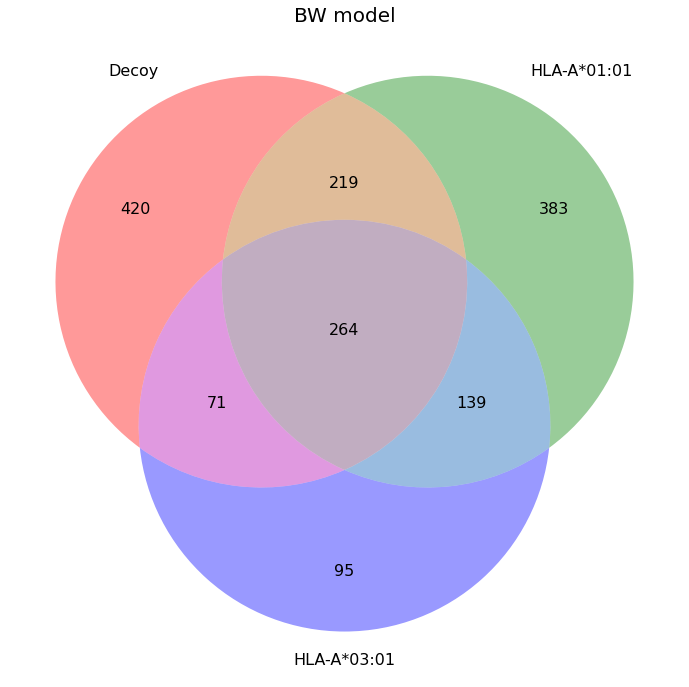

In [78]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(decoy_bw_paths_df, allele1_bw_paths_df, allele2_bw_paths_df, ax, allele1, allele2)
ax.set_title('BW model',  fontsize=title_font_size)



Text(0.5, 1.0, 'V model')

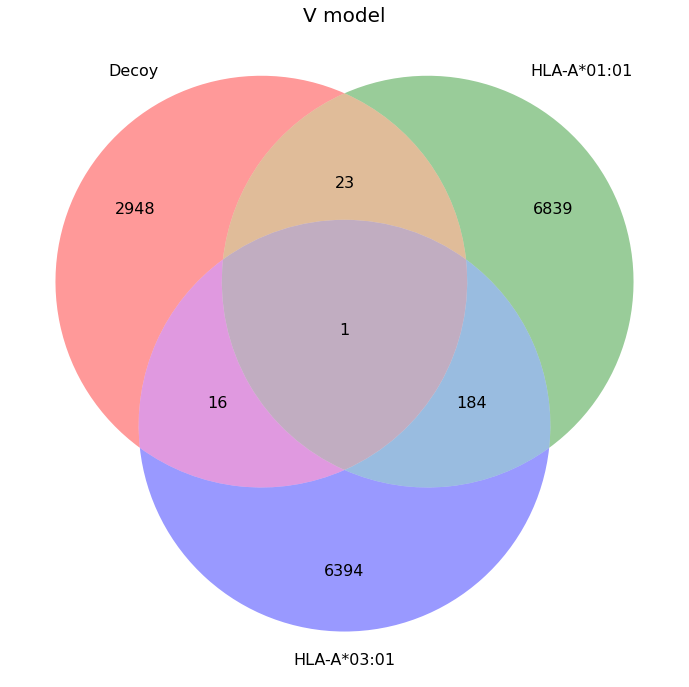

In [79]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(decoy_v_paths_df, allele1_v_paths_df, allele2_v_paths_df, ax, allele1, allele2)
ax.set_title('V model',  fontsize=title_font_size)


In [80]:
allele2_v_paths_df['peptide_cnts'].value_counts()

1    6013
2     482
3      67
4      28
5       4
6       1
Name: peptide_cnts, dtype: int64

In [81]:
pd.DataFrame(v_model.dense_transition_matrix())

,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
0,0.000000,0.033028,0.011430,0.008468,0.035636,3.359892e-01,0.102821,0.227509,2.092880e-01,3.582927e-02,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
1,0.190417,0.000000,0.019000,0.019140,0.014300,2.297836e-01,0.160845,0.187444,1.790693e-01,2.095794e-23,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
2,0.139057,0.031673,0.000000,0.010434,0.051793,3.799322e-01,0.094961,0.246648,6.173217e-19,4.550262e-02,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
3,0.057114,0.012474,0.015420,0.000000,0.092972,3.624052e-01,0.087308,0.186798,1.855102e-01,6.595912e-24,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
4,0.179966,0.050791,0.009352,0.009271,0.000000,3.178999e-01,0.167654,0.214841,1.741918e-22,5.022471e-02,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.077339,0.001124,6.642747e-02,3.156949e-02,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
6,0.000000,0.000000,0.000000,0.000000,0.000000,2.352539e-03,0.000000,0.000010,6.258904e-02,1.848606e-03,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
7,0.000000,0.000000,0.000000,0.000000,0.000000,2.613462e-05,0.058594,0.000000,5.727424e-02,2.751848e-05,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
8,0.000000,0.000000,0.000000,0.000000,0.000000,3.271228e-09,0.062971,0.001442,0.000000e+00,3.006972e-03,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
9,0.000000,0.000000,0.000000,0.000000,0.000000,4.218109e-02,0.058094,0.027995,2.914472e-02,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000


In [82]:
pd.DataFrame(new_v_model.dense_transition_matrix())

,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
0,0.000000,0.000000,0.0,0.0,0.000000,0.375000,0.125000,0.250000,0.250000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000
1,0.200000,0.000000,0.0,0.0,0.000000,0.200000,0.200000,0.200000,0.200000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000
2,0.111111,0.000000,0.0,0.0,0.111111,0.444444,0.111111,0.222222,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000
3,0.090909,0.000000,0.0,0.0,0.090909,0.363636,0.090909,0.181818,0.181818,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000
4,0.181818,0.090909,0.0,0.0,0.000000,0.272727,0.181818,0.181818,0.000000,0.090909,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000
5,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.090909,0.000000,0.090909,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000
6,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.083333,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000
7,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.090909,0.000000,0.090909,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000
8,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.100000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000
9,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.111111,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000


## Maybe need another sorting

In [35]:
decoy_v_paths_df

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts,exp_prob
0,grouped_model-start>s000>s005>s014>s017>s016>s...,-10.712701,-0.973882,9,-28.347163,1,2.226040e-05
1,grouped_model-start>s000>s005>s013>s017>s016>s...,-10.717674,-0.974334,9,-28.607292,9,2.214999e-05
2,grouped_model-start>s000>s008>s014>s017>s016>s...,-10.821247,-0.983750,9,-30.335843,11,1.997064e-05
3,grouped_model-start>s000>s007>s014>s017>s016>s...,-10.882990,-0.989363,9,-30.252498,5,1.877489e-05
4,grouped_model-start>s000>s005>s013>s010>s017>s...,-10.892385,-0.990217,9,-28.341529,2,1.859934e-05
...,...,...,...,...,...,...,...
653618,grouped_model-start>s004>s003>s006>s012>s014>s...,-29.775507,-2.706864,9,-41.994170,1,1.171282e-13
653619,grouped_model-start>s002>s003>s002>s004>s005>s...,-29.828904,-2.711719,9,-40.865855,1,1.110380e-13
653620,grouped_model-start>s001>s003>s002>s006>s013>s...,-29.980797,-2.725527,9,-40.145774,1,9.539050e-14
653621,grouped_model-start>s002>s003>s000>s006>s010>s...,-31.135519,-2.830502,9,-44.688708,1,3.006185e-14


In [42]:
decoy_v_paths_df.sort_values(by='peptide_cnts', ascending = False)

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts,exp_prob
3089,grouped_model-start>s000>s008>s014>s017>s023>s...,-12.773361,-1.161215,9,-30.699776,59,2.835304e-06
3489,grouped_model-start>s000>s007>s014>s017>s023>s...,-12.835104,-1.166828,9,-31.821809,47,2.665540e-06
6681,grouped_model-start>s000>s007>s013>s017>s023>s...,-13.216147,-1.201468,9,-32.339629,41,1.820959e-06
5658,grouped_model-start>s000>s007>s014>s017>s023>s...,-13.113078,-1.192098,9,-31.600861,34,2.018657e-06
272,grouped_model-start>s000>s008>s014>s017>s023>s...,-11.823864,-1.074897,9,-29.998056,33,7.327590e-06
...,...,...,...,...,...,...,...
253678,grouped_model-start>s000>s002>s000>s007>s011>s...,-18.738057,-1.561505,10,-36.917020,1,7.280567e-09
253677,grouped_model-start>s000>s007>s013>s017>s019>s...,-17.176540,-1.561504,9,-36.622258,1,3.469950e-08
253676,grouped_model-start>s000>s006>s014>s017>s016>s...,-18.738044,-1.561504,10,-33.376468,1,7.280664e-09
253675,grouped_model-start>s004>s000>s006>s012>s014>s...,-17.176540,-1.561504,9,-29.978159,1,3.469953e-08


In [49]:
(decoy_v_paths_df['peptide_cnts'] > 1).value_counts()

False    566081
True      87542
Name: peptide_cnts, dtype: int64

In [50]:
(allele1_v_paths_df['peptide_cnts'] > 1).value_counts()

False    6745
True      343
Name: peptide_cnts, dtype: int64

In [51]:
(allele2_v_paths_df['peptide_cnts'] > 1).value_counts()

False    6069
True      556
Name: peptide_cnts, dtype: int64

<AxesSubplot:>

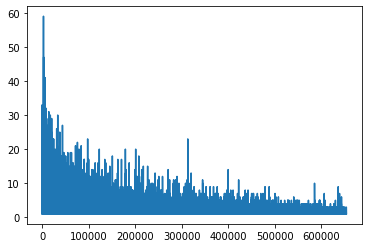

In [ ]:
decoy_v_paths_df['peptide_cnts'].plot()

In [70]:
filtered_decoy_paths = decoy_v_paths_df[(decoy_v_paths_df['peptide_cnts'] > 1)]
filtered_allele1_paths = allele1_v_paths_df[(allele1_v_paths_df['peptide_cnts'] > 1)]
filtered_allele2_paths = allele2_v_paths_df[(allele2_v_paths_df['peptide_cnts'] > 1)]

Text(0.5, 1.0, 'V model')

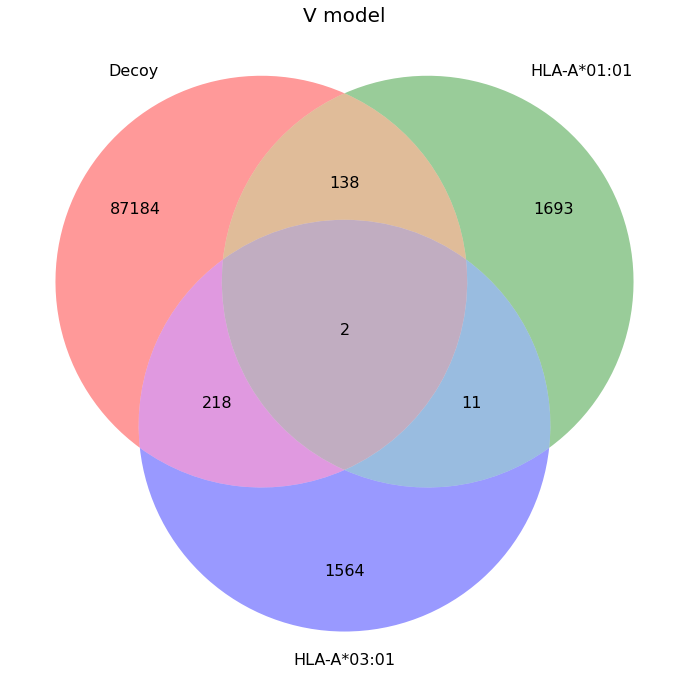

In [71]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(filtered_decoy_paths, allele1_v_paths_df, allele2_v_paths_df,ax, allele1, allele2)
ax.set_title('V model',  fontsize=title_font_size)


In [59]:
sorted_decoy_v_paths_df = decoy_v_paths_df.sort_values(by='mean_viterbi', ascending = False)
sorted_decoy_v_paths_df

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts,exp_prob
101250,grouped_model-start>s003>s007>s008>s011>s016>s...,-15.648113,-1.422556,9,-20.426795,1,1.599967e-07
18674,grouped_model-start>s003>s005>s011>s017>s016>s...,-13.941633,-1.267421,9,-21.247421,1,8.815069e-07
976,grouped_model-start>s000>s005>s008>s014>s017>s...,-12.246533,-1.113321,9,-21.517653,1,4.801738e-06
3147,grouped_model-start>s000>s008>s011>s017>s016>s...,-12.782616,-1.162056,9,-21.530819,1,2.809187e-06
3627,grouped_model-start>s000>s005>s009>s011>s014>s...,-12.856399,-1.168764,9,-21.665050,1,2.609378e-06
...,...,...,...,...,...,...,...
474418,grouped_model-start>s002>s006>s013>s019>s018>s...,-20.985399,-1.748783,10,-57.470355,1,7.694082e-10
449672,grouped_model-start>s003>s008>s006>s013>s019>s...,-20.693128,-1.724427,10,-58.719402,1,1.030597e-09
455342,grouped_model-start>s003>s007>s006>s013>s019>s...,-20.758252,-1.729854,10,-59.276576,2,9.656185e-10
556469,grouped_model-start>s000>s002>s006>s013>s019>s...,-22.195689,-1.849641,10,-59.457991,1,2.293690e-10


Text(0.5, 1.0, 'V model')

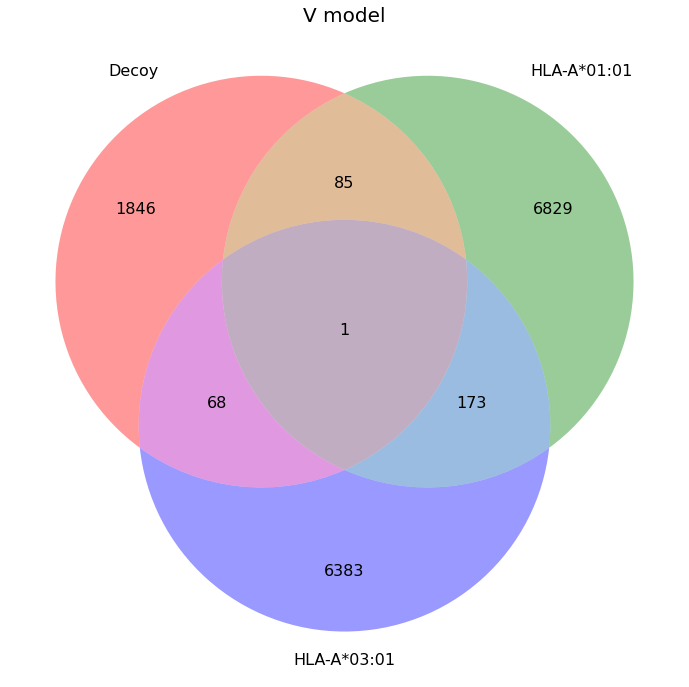

In [60]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(sorted_decoy_v_paths_df[:2000], allele1_v_paths_df, allele2_v_paths_df,ax, allele1, allele2)
ax.set_title('V model',  fontsize=title_font_size)

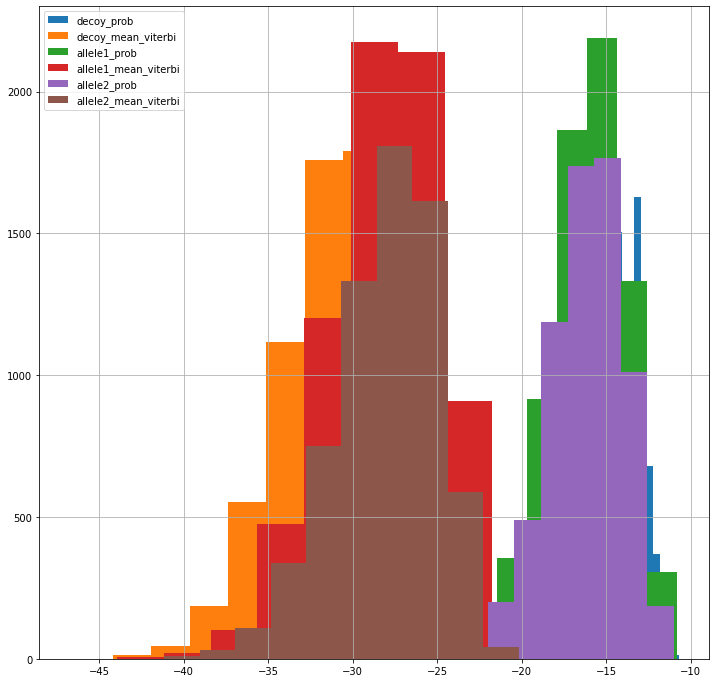

In [39]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[12, 12])
        
decoy_v_paths_df['prob'][:7000].hist().plot(ax=ax, )
decoy_v_paths_df['mean_viterbi'][:7000].hist().plot(ax=ax, )
allele1_v_paths_df['prob'].hist().plot(ax=ax, )
allele1_v_paths_df['mean_viterbi'].hist().plot(ax=ax, )

allele2_v_paths_df['prob'].hist().plot(ax=ax, )
allele2_v_paths_df['mean_viterbi'].hist().plot(ax=ax, )

plt.legend(['decoy_prob', 'decoy_mean_viterbi', 'allele1_prob', 'allele1_mean_viterbi', 'allele2_prob', 'allele2_mean_viterbi'])

In [28]:
paths_df['exp_prob'] = np.exp(paths_df['prob'])


In [29]:
paths_df['exp_prob'].cumsum().iloc[10]

0.06277501821407636

In [30]:
paths_df['exp_prob'].cumsum().iloc[1000]

0.6892319261925545

<AxesSubplot:>

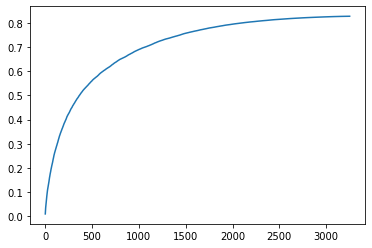

In [31]:
paths_df['exp_prob'].cumsum().plot()

<AxesSubplot:>

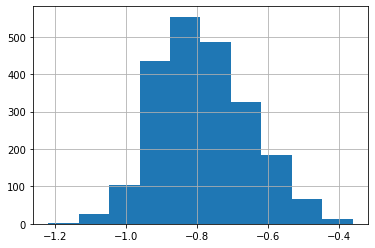

In [35]:
paths_df['normalized_prob'].hist()

<AxesSubplot:>

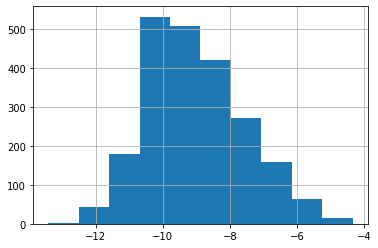

In [37]:
paths_df['prob'].hist()

In [28]:
paths_df.head(20)

,path,prob,normalized_prob,len,exp_prob
0,grouped_model-start>s001>s002>s005>s010>s012>s...,-4.348953,-0.362413,10,0.012920
1,grouped_model-start>s001>s002>s005>s010>s013>s...,-4.796836,-0.399736,10,0.008256
2,grouped_model-start>s001>s002>s005>s010>s012>s...,-4.798295,-0.399858,10,0.008244
3,grouped_model-start>s001>s002>s005>s010>s011>s...,-4.443446,-0.403950,9,0.011755
4,grouped_model-start>s001>s002>s005>s010>s014>s...,-4.628137,-0.420740,9,0.009773
5,grouped_model-start>s004>s009>s006>s010>s012>s...,-5.095926,-0.424660,10,0.006122
6,grouped_model-start>s001>s002>s005>s013>s011>s...,-4.740401,-0.430946,9,0.008735
7,grouped_model-start>s001>s002>s005>s010>s012>s...,-5.180728,-0.431727,10,0.005624
8,grouped_model-start>s001>s002>s005>s010>s012>s...,-5.207980,-0.433998,10,0.005473
9,grouped_model-start>s001>s002>s005>s010>s013>s...,-5.242446,-0.436870,10,0.005287


<AxesSubplot:>

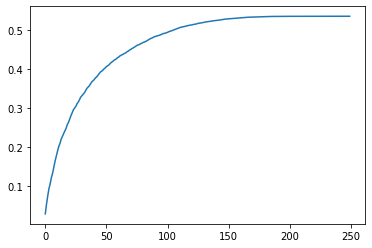

In [36]:
df_bw_paths['exp_prob'].cumsum().plot()

<AxesSubplot:ylabel='exp_prob'>

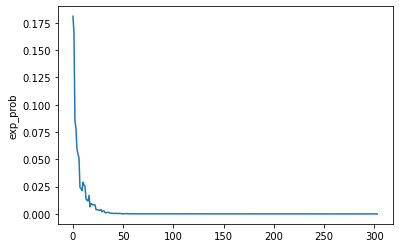

In [37]:
import seaborn as sns
sns.lineplot(data=df_bwv_paths, x=df_bwv_paths.index.values, y='exp_prob')

<AxesSubplot:ylabel='exp_prob'>

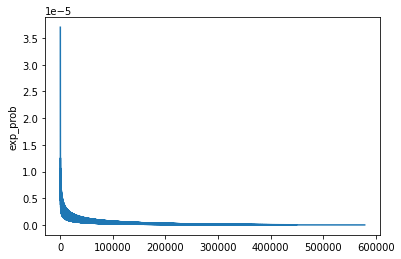

In [38]:
sns.lineplot(data=df_v_paths, x=df_v_paths.index.values, y='exp_prob')

<AxesSubplot:ylabel='exp_prob'>

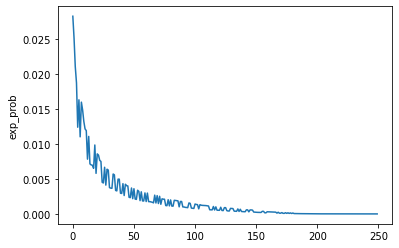

In [39]:
sns.lineplot(data=df_bw_paths, x=df_bw_paths.index.values, y='exp_prob')

In [124]:
#paths probs 3 per position
df_bw_paths.describe()

,prob,exp_prob
count,19683.000000,1.968300e+04
mean,-10.857784,5.080526e-05
std,1.630386,6.636808e-05
min,-15.265151,2.346548e-07
25%,-12.137985,5.352296e-06
50%,-10.528127,2.677272e-05
75%,-9.574887,6.945114e-05
max,-7.397044,6.130621e-04
